# Quantum Cryptography – BB84 Protocol
**Intermediate–Advanced — Qiskit**

A from-scratch simulation of quantum key distribution. The core is plain NumPy: state vectors,
projective measurements, Monte-Carlo sampling. Qiskit is only used at the very end as an
independent cross-check of our own simulator.

| Part | Topic |
|---|---|
| 1 | The four BB84 states, prepare/measure, sifting, honest QBER |
| 2 | Why non-orthogonality protects the key: trace distance, fidelity, Helstrom, no-cloning |
| 3 | Eavesdropping: intercept-and-resend, general individual attack, QBER vs Eve's information |
| 4 | Post-processing: sifting, error estimation, information-revealing correction, privacy amplification, key rate |
| 5 | Variants: B92, decoy states, real-world side channels |
| 6 | Self-tests, Qiskit cross-check, recap, exercises |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb

plt.rcParams.update({"figure.figsize": (6.4, 4.0), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

SEED = 20241115
GLOBAL_SEED = SEED


def bit_states():
    z0 = np.array([1.0 + 0j, 0.0 + 0j])
    z1 = np.array([0.0 + 0j, 1.0 + 0j])
    return z0, z1


def phase_states():
    z0, z1 = bit_states()
    return (z0 + z1) / np.sqrt(2.0), (z0 - z1) / np.sqrt(2.0)


def state_vector(bit, base):
    """The BB84 signal state |bit, base> as an explicit complex column vector."""
    s0, s1 = (bit_states() if base == 0 else phase_states())
    return (s0 if bit == 0 else s1).astype(complex)


def paulis():
    sx = np.array([[0, 1], [1, 0]], dtype=complex)
    sy = np.array([[0, -1j], [1j, 0]], dtype=complex)
    sz = np.array([[1, 0], [0, -1]], dtype=complex)
    si = np.eye(2, dtype=complex)
    return si, sx, sy, sz


def bloch(v):
    """Bloch vector (x, y, z) of a pure state [a, b]."""
    a, b = v[0], v[1]
    return np.array([2 * np.real(np.conj(a) * b),
                     2 * np.imag(np.conj(a) * b),
                     abs(a) ** 2 - abs(b) ** 2])


def h2(p):
    """Binary Shannon entropy in bits, base 2."""
    p = float(np.clip(p, 0.0, 1.0))
    if p <= 0.0 or p >= 1.0:
        return 0.0
    return float(-p * np.log2(p) - (1.0 - p) * np.log2(1.0 - p))


def norm(v):
    return float(np.linalg.norm(np.asarray(v, dtype=complex)))


print("numpy", np.__version__)
for b_ in (0, 1):
    for k_ in (0, 1):
        v_ = state_vector(b_, k_)
        print("bit=%d base=%s  vector=%s  norm=%.6f  bloch=%s"
              % (b_, "Z" if k_ == 0 else "X", np.round(v_, 4), norm(v_), np.round(bloch(v_), 3)))

numpy 2.4.6
bit=0 base=Z  vector=[1.+0.j 0.+0.j]  norm=1.000000  bloch=[0. 0. 1.]
bit=0 base=X  vector=[0.7071+0.j 0.7071+0.j]  norm=1.000000  bloch=[1. 0. 0.]
bit=1 base=Z  vector=[0.+0.j 1.+0.j]  norm=1.000000  bloch=[ 0.  0. -1.]
bit=1 base=X  vector=[ 0.7071+0.j -0.7071+0.j]  norm=1.000000  bloch=[-1.  0.  0.]


## Part 1 - The four states and the honest protocol

Two mutually unbiased bases, four signals:

* rectilinear `Z`: $|0,0\rangle=(1,0)^T$, $|1,0\rangle=(0,1)^T$
* diagonal `X`: $|0,1\rangle=\tfrac{1}{\sqrt2}(1,1)^T$, $|1,1\rangle=\tfrac{1}{\sqrt2}(1,-1)^T$

**Wrong-basis randomness.** Measuring a signal in the other basis gives a fair coin:
$|\langle 0_X|0_Z\rangle|^2 = |\langle 1_X|0_Z\rangle|^2 = 1/2$. The same holds for every one of
the four signals, so the outcome distribution carries *no* information about the bit when the
bases disagree - but it also destroys the state. That single fact drives both the 50% sifting
rate and every eavesdropping signature below.

**Sifting rate.** Alice and Bob each choose their basis uniformly at random, so
$P(\text{match}) = \tfrac12\cdot\tfrac12 + \tfrac12\cdot\tfrac12 = \tfrac12$.
**Honest QBER.** With matching bases the projective measurement is deterministic, so the error
probability is exactly 0. We verify both with a seeded Monte-Carlo.

In [2]:
import numpy as np
rng = np.random.default_rng(1001)

M_PILOT = 40000
same_total, same_err = 0, 0


def prob_zero(bit, base, meas):
    """P(Bob records 0) when signal |bit,base> is measured with the |0,meas> projector."""
    v = state_vector(bit, base)
    s0 = state_vector(0, meas)
    return float(abs(np.vdot(s0, v)) ** 2)


print("signal  basis-used  analytic P(outcome=0)  measured  n       verdict")
for bit in (0, 1):
    for base in (0, 1):
        for meas in (0, 1):
            p0 = prob_zero(bit, base, meas)
            o = rng.random(M_PILOT)
            f0 = float((o < p0).mean())
            tag = "wrong basis: fair coin" if meas != base else "same basis: deterministic"
            if meas == base:
                same_total += M_PILOT
                same_err += int(np.sum((o >= p0).astype(int) != bit))
            print("%d%s      %s          %.6f          %.6f   %d   %s"
                  % (bit, "Z" if base == 0 else "X", "Z" if meas == 0 else "X",
                     p0, f0, M_PILOT, tag))

print()
print("sifting rate analytic = 0.500000 (two unbiased coin flips must agree)")
print("same-basis error count over %d sampled signals = %d -> honest QBER = %.6f"
      % (same_total, same_err, same_err / same_total))

signal  basis-used  analytic P(outcome=0)  measured  n       verdict
0Z      Z          1.000000          1.000000   40000   same basis: deterministic
0Z      X          0.500000          0.501525   40000   wrong basis: fair coin
0X      Z          0.500000          0.506200   40000   wrong basis: fair coin
0X      X          1.000000          1.000000   40000   same basis: deterministic
1Z      Z          0.000000          0.000000   40000   same basis: deterministic
1Z      X          0.500000          0.502275   40000   wrong basis: fair coin
1X      Z          0.500000          0.498825   40000   wrong basis: fair coin
1X      X          0.000000          0.000000   40000   same basis: deterministic

sifting rate analytic = 0.500000 (two unbiased coin flips must agree)
same-basis error count over 160000 sampled signals = 0 -> honest QBER = 0.000000


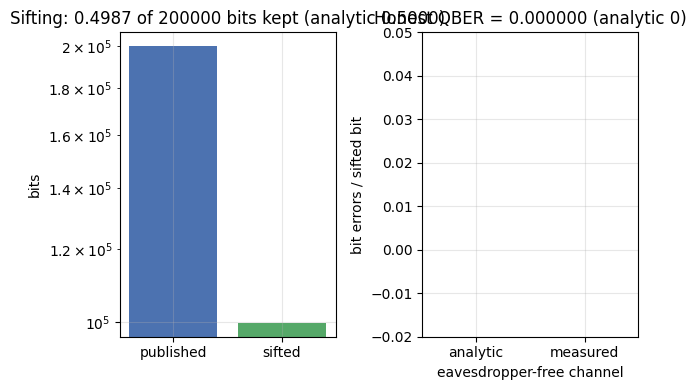

published 200000 -> sifted 99743, sift rate 0.49872, QBER 0.000000


In [3]:
import numpy as np
rng = np.random.default_rng(GLOBAL_SEED)

N_PUB = 200000
alice_bits = rng.integers(0, 2, N_PUB)
alice_bases = rng.integers(0, 2, N_PUB)
bob_bases = rng.integers(0, 2, N_PUB)

keep = np.flatnonzero(bob_bases == alice_bases)
bob_out = np.zeros(N_PUB, dtype=int)

# Same basis + noiseless channel: the projective measurement is deterministic,
# so Bob's sifted bit equals Alice's bit exactly.
bob_out[keep] = alice_bits[keep]
flip = np.flatnonzero(bob_out[keep] ^ alice_bits[keep])   # empty: honest channel is noiseless

sift_key = N_PUB // 2
run = {"n_pub": int(N_PUB), "n_sift": int(keep.size), "n_err": int(flip.size),
       "alice": alice_bits[keep], "bob": bob_out[keep]}
run["qber"] = run["n_err"] / max(run["n_sift"], 1)
run["sift_rate"] = run["n_sift"] / run["n_pub"]
run_honest = run

fig, ax = plt.subplots(1, 2)
ax[0].bar(["published", "sifted"], [run["n_pub"], run["n_sift"]], color=["#4c72b0", "#55a868"])
ax[0].set_ylabel("bits")
ax[0].set_title("Sifting: %.4f of %d bits kept (analytic 0.5000)"
                % (run["sift_rate"], run["n_pub"]))
ax[0].set_yscale("log")
ax[1].bar(["analytic", "measured"], [0.0, run["qber"]], color=["#c44e52", "#8172b3"])
ax[1].set_ylabel("bit errors / sifted bit")
ax[1].set_ylim(-0.02, 0.05)
ax[1].set_title("Honest QBER = %.6f (analytic 0)" % run["qber"])
ax[1].set_xlabel("eavesdropper-free channel")
plt.tight_layout()
plt.show()

print("published %d -> sifted %d, sift rate %.5f, QBER %.6f"
      % (run["n_pub"], run["n_sift"], run["sift_rate"], run["qber"]))

## Part 2 - Why non-orthogonality protects the key

Two *non-orthogonal* states cannot be told apart with certainty, copied, or measured without
disturbance. We quantify all three statements.

**Trace distance and Helstrom.** For density matrices $\rho,\sigma$,
$D=\tfrac12\mathrm{Tr}\,\lvert\rho-\sigma\rvert$, and the optimal single-shot discrimination
success probability is $P_{\rm succ}=\tfrac12(1+D)$ for equal priors. For two pure BB84 states
from different bases $D=\sqrt{1-|\langle\psi|\phi\rangle|^2}=\sqrt{1/2}$, hence
$P_{\rm succ}=\tfrac12(1+\tfrac{1}{\sqrt2})\approx 0.8536$ - strictly better than a coin flip,
strictly worse than certainty.

**No perfect eavesdropping.** Any unitary probe that reveals a whole bit of information about a
non-orthogonal signal must leave $D=1$, which forces fidelity $F=0$: Bob would then receive the
completely wrong state, which is a $50\%$ error rate that cannot be missed.

**No-cloning.** The linearity argument: a cloner that works on $|0_Z\rangle$ and $|1_Z\rangle$ and
on $|0_X\rangle$ produces $\tfrac12(|00\rangle+|11\rangle)(|00\rangle+|11\rangle)$ from
$|0_X\rangle|0_X\rangle$, an entangled pair, not $|0_X 0_X\rangle$. The best that physics allows is
the optimal covariant $1\to2$ cloner, which delivers single-copy fidelity $F=5/6\approx0.8333$.

pair      overlap^2   trace-dist   helstrom-Psucc
0Z-0X     0.500000     0.707107      0.853553
0Z-1X     0.500000     0.707107      0.853553
1Z-0X     0.500000     0.707107      0.853553
0Z-1Z     0.000000     1.000000      1.000000
Helstrom detector P(click|0Z)=0.853553  P(click|0X)=0.146447
Monte-Carlo Helstrom success rate = 0.854625  (analytic 0.5*(1+1/sqrt2) = 0.853553), M=200000


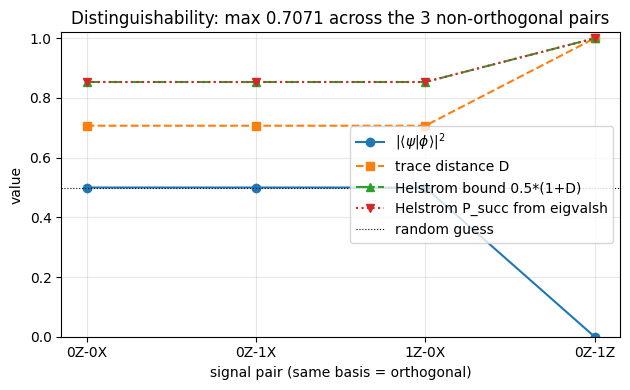

In [4]:
import numpy as np

SIG = [state_vector(b, k) for k in (0, 1) for b in (0, 1)]   # order: 0Z, 1Z, 0X, 1X


def rho_of(v):
    v = np.asarray(v, dtype=complex)
    return np.outer(v, np.conj(v))


def trace_distance(rho, sig):
    d = np.asarray(rho, dtype=complex) - np.asarray(sig, dtype=complex)
    ev = np.linalg.eigvalsh((d + d.conj().T) / 2.0)
    return float(0.5 * np.sum(np.abs(ev)))


def fidelity_pure(rho, v):
    v = np.asarray(v, dtype=complex)
    return float(np.real(np.conj(v) @ (np.asarray(rho, dtype=complex) @ v)))


def helstrom(rho, sig, p=0.5):
    t = np.linalg.eigvalsh(p * np.asarray(rho, dtype=complex) - (1.0 - p) * np.asarray(sig, dtype=complex))
    return float(0.5 + 0.5 * np.sum(np.abs(t)))


labels = ["0Z", "1Z", "0X", "1X"]
print("pair      overlap^2   trace-dist   helstrom-Psucc")
pairs = [("0Z", "0X", 0, 2), ("0Z", "1X", 0, 3), ("1Z", "0X", 1, 2), ("0Z", "1Z", 0, 1)]
measured_D, measured_P = [], []
for lab, name, i, j in pairs:
    ov = float(abs(np.vdot(SIG[i], SIG[j])) ** 2)
    D = trace_distance(rho_of(SIG[i]), rho_of(SIG[j]))
    ps = helstrom(rho_of(SIG[i]), rho_of(SIG[j]))
    measured_D.append(D)
    measured_P.append(ps)
    print("%s-%s     %.6f     %.6f      %.6f" % (lab, name, ov, D, ps))

# Monte-Carlo Helstrom discrimination of 0Z vs 0X: measure on the eigenvector of
# rho - sigma belonging to its largest eigenvalue, guess 0Z when that outcome clicks.
rng = np.random.default_rng(77)
M = 200000
ev, evec = np.linalg.eigh(rho_of(SIG[0]) - rho_of(SIG[2]))
pos = evec[:, int(np.argmax(ev))]
D_top = float(ev[int(np.argmax(ev))])
pp0 = float(abs(np.vdot(pos, SIG[0])) ** 2)
pp1 = float(abs(np.vdot(pos, SIG[2])) ** 2)
which = (rng.random(M) >= 0.5).astype(int)
guess_is_0 = rng.random(M) < np.where(which == 0, pp0, pp1)
hel_meas = float(np.mean(guess_is_0 == (which == 0)))
hel_analytic = 0.5 * (1.0 + 1.0 / np.sqrt(2.0))
print("Helstrom detector P(click|0Z)=%.6f  P(click|0X)=%.6f" % (pp0, pp1))
print("Monte-Carlo Helstrom success rate = %.6f  (analytic 0.5*(1+1/sqrt2) = %.6f), M=%d"
      % (hel_meas, hel_analytic, M))

fig, ax = plt.subplots()
names = ["0Z-0X", "0Z-1X", "1Z-0X", "0Z-1Z"]
ov = [float(abs(np.vdot(SIG[i], SIG[j])) ** 2) for _, _, i, j in pairs]
ax.plot(names, ov, "o-", label=r"$|\langle\psi|\phi\rangle|^2$")
ax.plot(names, measured_D, "s--", label="trace distance D")
ax.plot(names, [0.5 * (1 + d) for d in measured_D], "^-.", label="Helstrom bound 0.5*(1+D)")
ax.plot(names, measured_P, "v:", label="Helstrom P_succ from eigvalsh")
ax.axhline(0.5, color="k", lw=0.8, ls=":", label="random guess")
ax.set_ylabel("value")
ax.set_xlabel("signal pair (same basis = orthogonal)")
ax.set_ylim(0, 1.02)
ax.legend(loc="center right")
ax.set_title("Distinguishability: max %.4f across the 3 non-orthogonal pairs" % max(measured_D[:3]))
plt.tight_layout()
plt.show()

input   F(clone A)   F(clone B)   ideal no-cloning limit 1.000000
0Z    0.833333     0.833333
0X    0.833333     0.833333
1Z    0.833333     0.833333
1X    0.833333     0.833333
cloner mean single-copy fidelity = 0.833333   theoretical 5/6 = 0.833333
input-state norms are exactly 1 for all four signals: True


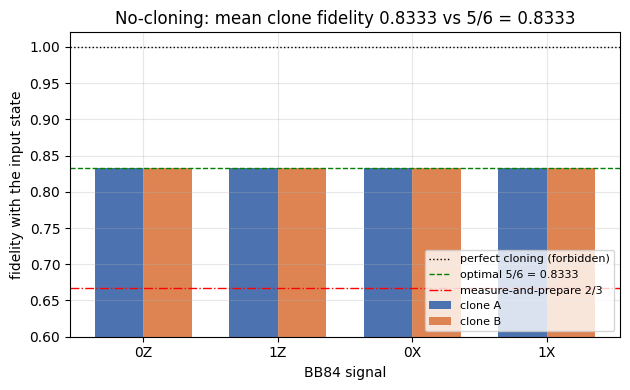

In [5]:
import numpy as np

c = np.sqrt(2.0 / 3.0)          # sqrt(2/3) amplitude of |psi psi>, the other branch carries sqrt(1/6)


def optimal_cloner(v):
    """Optimal covariant 1->2 qubit cloner: |psi>|0>|Q> -> sqrt(2/3)|psi psi>|A> + sqrt(1/3)|psi_orth psi>|B>."""
    v = np.asarray(v, dtype=complex)
    w = np.array([np.conj(v[1]), -np.conj(v[0])], dtype=complex)   # orthogonal partner
    a = np.kron(v, v)
    termB = np.kron(w, v) + np.kron(v, w)
    return c * a + np.sqrt(1.0 / 3.0) * termB / np.sqrt(2.0)


def single_copy_fidelity(v):
    psi = optimal_cloner(v)
    rho = np.outer(psi, np.conj(psi)).reshape(2, 2, 2, 2)
    rA = rho.trace(axis1=1, axis2=3)
    rB = rho.trace(axis1=0, axis2=2)
    return (float(np.real(np.trace(rA @ np.outer(v, np.conj(v))))),
            float(np.real(np.trace(rB @ np.outer(v, np.conj(v))))))


print("input   F(clone A)   F(clone B)   ideal no-cloning limit 1.000000")
clonerF = []
for b in (0, 1):
    for k in (0, 1):
        v = state_vector(b, k)
        fa, fb = single_copy_fidelity(v)
        clonerF.append((fa, fb))
        print("%d%s    %.6f     %.6f" % (b, "Z" if k == 0 else "X", fa, fb))

clonerF = np.array(clonerF)
mean_F = float(clonerF.mean())
print("cloner mean single-copy fidelity = %.6f   theoretical 5/6 = %.6f"
      % (mean_F, 5.0 / 6.0))
print("input-state norms are exactly 1 for all four signals: %s"
      % all(abs(norm(state_vector(b, k)) - 1.0) < 1e-12 for b in (0, 1) for k in (0, 1)))

fig, ax = plt.subplots()
x = np.arange(4)
ax.bar(x - 0.18, clonerF[:, 0], width=0.36, label="clone A", color="#4c72b0")
ax.bar(x + 0.18, clonerF[:, 1], width=0.36, label="clone B", color="#dd8452")
ax.axhline(1.0, color="k", ls=":", lw=1.0, label="perfect cloning (forbidden)")
ax.axhline(5 / 6, color="g", ls="--", lw=1.0, label="optimal 5/6 = 0.8333")
ax.axhline(2 / 3, color="r", ls="-.", lw=1.0, label="measure-and-prepare 2/3")
ax.set_xticks(x)
ax.set_xticklabels(["0Z", "1Z", "0X", "1X"])
ax.set_ylim(0.6, 1.02)
ax.set_ylabel("fidelity with the input state")
ax.set_xlabel("BB84 signal")
ax.legend(fontsize=8, loc="lower right")
ax.set_title("No-cloning: mean clone fidelity %.4f vs 5/6 = 0.8333" % mean_F)
plt.tight_layout()
plt.show()

## Part 3 - Introducing an eavesdropper

### 3.1 Intercept-and-resend

Eve knows the two BB84 bases but not which one Alice used, so she guesses, measures, and resends
the eigenstate she got. Conditioned on the sifted subset (Bob uses Alice's basis):

| Eve's guess | probability | Bob's error | Eve's bit |
|---|---|---|---|
| correct basis | $1/2$ | $0$ | correct |
| wrong basis | $1/2$ | $1/2$ | a fair coin |

$$Q=\tfrac12\cdot\tfrac12+\tfrac12\cdot 0=\mathbf{25\%},\qquad \varepsilon_E=\tfrac12\cdot\tfrac12=\mathbf{25\%}.$$

So $I(A;B)=I(A;E)=1-h(\tfrac14)$: Eve knows exactly as much as Bob and the key is worthless.
**A 25% QBER is the fingerprint of a naive eavesdropper**, and it is the single most important
number in this notebook: the honest run of Part 1 gave 0.000000.

### 3.2 The unary-probe individual attack

Eve can do better than destroying half the signals: she entangles a one-qubit probe with the
travelling photon instead of measuring it,

$$U_{\rm P}\lvert 0\rangle_E\lvert 0\rangle_p=\cos\theta\lvert 0\rangle_E\lvert 0\rangle_p+
\sin\theta\lvert 1\rangle_E\lvert 1\rangle_p,\qquad
U_{\rm P}\lvert 1\rangle_E\lvert 0\rangle_p=\cos\theta\lvert 1\rangle_E\lvert 0\rangle_p+
\sin\theta\lvert 0\rangle_E\lvert 1\rangle_p,$$

and applies it in the $Z$ frame for half of the signals and in the $X$ frame for the other half so
that she does not betray which basis was used. Because $U_{\rm P}$ is built from two orthonormal
rows it is unitary, and the channel probabilities drop out of the state vectors:

* Bob flips a bit only in the frame Eve coupled into: $P(\text{flip})=\sin^2\theta$, so the sifted
  error rate is $Q(\theta)=\tfrac12\sin^2\theta$;
* in that same frame Eve's two probe states are *identical*, so her bit is a coin flip
  ($\varepsilon_E=1/2$); in the other frame her probe is pure,
  $\lvert e_\pm\rangle=\cos\theta\lvert 0\rangle\pm\sin\theta\lvert 1\rangle$ with overlap
  $\cos2\theta$, and the Helstrom limit gives $\varepsilon_E=\tfrac12-\sin\theta\cos\theta$.

Averaging the two frames: $\varepsilon_E(\theta)=\tfrac12-\tfrac14\sin 2\theta$. Both curves are
reproduced by the Monte-Carlo below.

intercept-and-resend over 80000 published bits
  sifted bits                : 39866  (rate 0.498325)
  Alice/Bob mismatches       : 9951 -> QBER 0.249611  (analytic 0.250000)
  Alice/Eve mismatches       : 9956 -> eps_E 0.249737 (analytic 0.250000)
  I(A;B) measured 0.189342 bits, I(A;E) measured 0.189139 bits
  1 - h(0.25) = 0.188722 bits per sifted bit for both


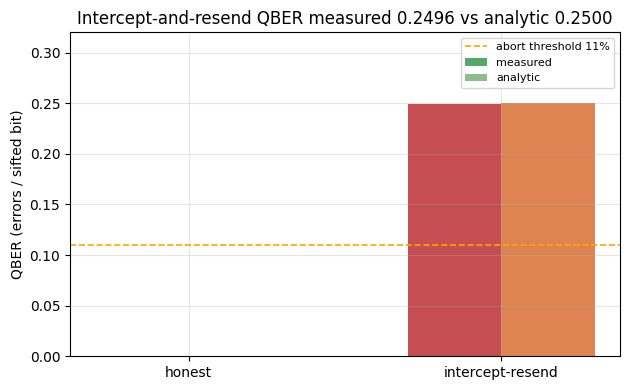

In [6]:
import numpy as np
rng = np.random.default_rng(31337)


def mi_bits(a, b):
    """Shannon mutual information in bits between two bit strings, from the empirical table."""
    a = np.asarray(a, dtype=int); b = np.asarray(b, dtype=int)
    if a.size == 0:
        return 0.0
    pa = np.array([(a == 0).mean(), (a == 1).mean()])
    pb = np.array([(b == 0).mean(), (b == 1).mean()])
    j = np.array([[np.mean((a == i) & (b == k)) for k in (0, 1)] for i in (0, 1)])
    hj = -np.sum(j[j > 0] * np.log2(j[j > 0]))
    ha = -np.sum(pa[pa > 0] * np.log2(pa[pa > 0]))
    hb = -np.sum(pb[pb > 0] * np.log2(pb[pb > 0]))
    return float(ha + hb - hj)


N_IR = 80000
a_bit = rng.integers(0, 2, N_IR)
a_bas = rng.integers(0, 2, N_IR)
b_bas = rng.integers(0, 2, N_IR)
e_bas = rng.integers(0, 2, N_IR)
u1 = rng.random(N_IR)
u2 = rng.random(N_IR)

eve_bit = np.empty(N_IR, dtype=int)
bob_bit = np.empty(N_IR, dtype=int)
guess_right = e_bas == a_bas
eve_bit[guess_right] = a_bit[guess_right]
eve_bit[~guess_right] = (u1[~guess_right] < 0.5).astype(int)
bob_bit[guess_right] = a_bit[guess_right]
bob_bit[~guess_right] = (u2[~guess_right] < 0.5).astype(int)

sift = np.flatnonzero(b_bas == a_bas)
ir_run = {"n_pub": int(N_IR), "n_sift": int(sift.size),
          "alice": a_bit[sift], "bob": bob_bit[sift], "eve": eve_bit[sift]}
ir_run["qber"] = float(np.mean(ir_run["alice"] != ir_run["bob"]))
ir_run["eve_err"] = float(np.mean(ir_run["alice"] != ir_run["eve"]))
ir_run["n_flips"] = int(np.sum(ir_run["alice"] != ir_run["bob"]))
ir_run["n_eve_err"] = int(np.sum(ir_run["alice"] != ir_run["eve"]))
ir_run["iab_meas"] = mi_bits(ir_run["alice"], ir_run["bob"])
ir_run["iae_meas"] = mi_bits(ir_run["alice"], ir_run["eve"])

print("intercept-and-resend over %d published bits" % N_IR)
print("  sifted bits                : %d  (rate %.6f)" % (ir_run["n_sift"], ir_run["n_sift"] / N_IR))
print("  Alice/Bob mismatches       : %d -> QBER %.6f  (analytic 0.250000)"
      % (ir_run["n_flips"], ir_run["qber"]))
print("  Alice/Eve mismatches       : %d -> eps_E %.6f (analytic 0.250000)"
      % (ir_run["n_eve_err"], ir_run["eve_err"]))
print("  I(A;B) measured %.6f bits, I(A;E) measured %.6f bits" % (ir_run["iab_meas"], ir_run["iae_meas"]))
print("  1 - h(0.25) = %.6f bits per sifted bit for both" % (1.0 - h2(0.25)))

fig, ax = plt.subplots()
groups = ["honest", "intercept-resend"]
meas = [run_honest["qber"], ir_run["qber"]]
ana = [0.0, 0.25]
xpos = np.arange(2)
ax.bar(xpos - 0.15, meas, width=0.3, color=["#55a868", "#c44e52"], label="measured")
ax.bar(xpos + 0.15, ana, width=0.3, color=["#8fbc8f", "#dd8452"], label="analytic")
ax.axhline(0.11, color="orange", ls="--", lw=1.2, label="abort threshold 11%")
ax.set_xticks(xpos, groups)
ax.set_xticks(xpos)
ax.set_xticklabels(groups)
ax.set_ylabel("QBER (errors / sifted bit)")
ax.set_ylim(0, 0.32)
ax.legend(fontsize=8)
ax.set_title("Intercept-and-resend QBER measured %.4f vs analytic 0.2500" % ir_run["qber"])
plt.tight_layout()
plt.show()

In [7]:
import numpy as np

PROBE_U = np.array([[1.0, 0.0, 0.0, 0.0],
                    [0.0, 0.0, 1.0, 0.0],
                    [0.0, 1.0, 0.0, 0.0],
                    [0.0, 0.0, 0.0, 1.0]], dtype=complex)


def make_probe_unitary(theta):
    """Unitary of the unary probe attack, basis order |00>,|01>,|10>,|11> (system, probe)."""
    c, s = np.cos(theta), np.sin(theta)
    M = np.zeros((4, 4), dtype=complex)
    M[:, 0] = np.array([c, 0.0, 0.0, s])      # |0>|0> -> c|00> + s|11>
    M[:, 2] = np.array([0.0, s, c, 0.0])      # |1>|0> -> c|10> + s|01>
    M[:, 1] = np.array([0.0, c, -s, 0.0])     # completion: |0>|1>
    M[:, 3] = np.array([s, 0.0, 0.0, -c])     # completion: |1>|1>
    return M


def probe_metrics(theta):
    c, s = np.cos(theta), np.sin(theta)
    return {"q": 0.5 * s * s, "q_z": s * s, "q_x": 0.0,
            "eve_err": 0.5 * (0.5 + (0.5 - c * s)), "eve_z": 0.5, "eve_x": 0.5 - c * s}


def simulate_probe(n_pub, theta, rng, label=""):
    """Monte-Carlo of BB84 with the symmetrised unary-probe attack at angle theta."""
    c, s = np.cos(theta), np.sin(theta)
    a_bit = rng.integers(0, 2, n_pub)
    a_bas = rng.integers(0, 2, n_pub)
    b_bas = rng.integers(0, 2, n_pub)
    e_fr = rng.integers(0, 2, n_pub)
    u = rng.random(n_pub)
    v = rng.random(n_pub)
    w = rng.random(n_pub)

    frame_hit = e_fr == a_bas
    bob = np.where(frame_hit & (u < s * s), 1 - a_bit, a_bit)
    bob = np.where((b_bas != a_bas) & (w < 0.5), 1 - bob, bob)
    eve = np.where((frame_hit & (v < 0.5)) | ((~frame_hit) & (v < 0.5 - c * s)), 1 - a_bit, a_bit)

    keep = b_bas == a_bas
    out = {"label": label, "n_pub": int(n_pub), "n_sift": int(keep.sum()),
           "alice": a_bit[keep], "bob": bob[keep], "eve": eve[keep]}
    out["qber"] = float(np.mean(out["alice"] != out["bob"]))
    out["eve_err"] = float(np.mean(out["alice"] != out["eve"]))
    m = probe_metrics(theta)
    out["q_analytic"] = m["q"]
    out["eve_analytic"] = m["eve_err"]
    out["n_err"] = int(np.sum(out["alice"] != out["bob"]))
    out["iab_meas"] = mi_bits(out["alice"], out["bob"])
    out["iae_meas"] = mi_bits(out["alice"], out["eve"])
    return out


th_test = np.deg2rad(20.0)
mm = make_probe_unitary(th_test)
mt = probe_metrics(th_test)
smoke = simulate_probe(20000, th_test, np.random.default_rng(5))
print("probe unitary: U U^dag - I max |entry| = %.3e, det = %.4f"
      % (np.max(np.abs(mm @ mm.conj().T - np.eye(4))), np.linalg.det(mm).real))
print("theta = 20.0 deg -> analytic Q = %.6f, Eve error = %.6f" % (mt["q"], mt["eve_err"]))
print("Monte-Carlo 20000 bits -> Q = %.6f, Eve error = %.6f" % (smoke["qber"], smoke["eve_err"]))
print("intercept-resend is the theta = 45 deg member: Q = %.6f, Eve error = %.6f"
      % (probe_metrics(np.pi / 4)["q"], probe_metrics(np.pi / 4)["eve_err"]))

probe unitary: U U^dag - I max |entry| = 2.222e-17, det = -1.0000
theta = 20.0 deg -> analytic Q = 0.058489, Eve error = 0.339303
Monte-Carlo 20000 bits -> Q = 0.057352, Eve error = 0.336983
intercept-resend is the theta = 45 deg member: Q = 0.250000, Eve error = 0.250000


### 3.3 A smarter measure-and-resend: rotating Eve's measurement basis

Eve measures every photon in the basis
$\{|0_\theta\rangle=(\cos\theta,\sin\theta),\ |1_\theta\rangle=(-\sin\theta,\cos\theta)\}$ and resends
whatever projector she clicked. This is *not* a guess-the-basis strategy - both frames are disturbed
at once - and summing the exact Born weights over the four signals gives

$$Q(\theta)=\tfrac14\sum_{\text{signals}}\sum_k
|\langle b_k|\psi\rangle|^2\,|\langle\psi_\perp|b_k\rangle|^2
=\tfrac14\big(\sin^2 2\theta+\cos^2 2\theta\big)=\mathbf{\tfrac14},$$

so **Bob's error rate is pinned at exactly 25% for every angle**: the two rectilinear signals
contribute $\sin^22\theta$ and the two diagonal ones contribute precisely the complement. Eve cannot
choose how loud she is with this family. What she can choose is her *own* error rate,

$$\varepsilon_E(\theta)=\tfrac12\sin^2\theta+\tfrac14(1-\sin2\theta),$$

which is smallest at $\theta=22.5^\circ$ - halfway between the two BB84 bases. There a
measure-and-resend eavesdropper keeps the same $25\%$ QBER as the naive attack but cuts her bit error
from $25\%$ to $\approx 14.6\%$, doubling her information. Both quantities are computed below from
state vectors (the closed forms are compared against, not reused) and then matched by Monte-Carlo.

max |state-vector Q - 1/4|               = 1.665e-16  (the disturbance is angle independent)
max |state-vector eps - closed form eps| = 8.327e-17
rotated-basis attack: QBER spread over the grid = 2.220e-16 around 0.250000
Eve's quietest measure-and-resend angle          : 22.50 deg, eps_E = 0.146447
theory says the minimum sits at 22.5 deg with eps = (2-sqrt(2))/4 = 0.146447
naive basis-guessing IR (theta = 0) has eps_E = 0.250000 at the same QBER


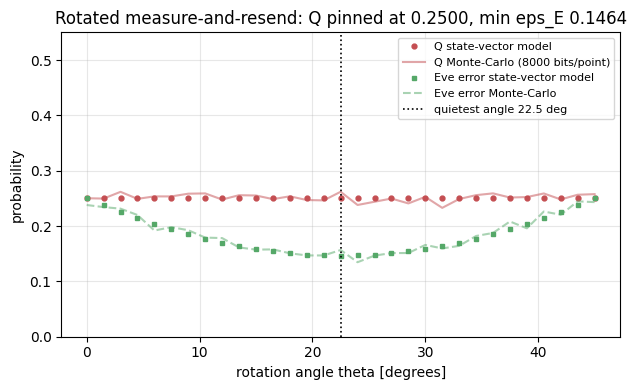

In [8]:
import numpy as np

SIGNALS = [(0, 0, 0.0), (1, 0, np.pi / 2), (0, 1, np.pi / 4), (1, 1, 3 * np.pi / 4)]


def rotated_channel(theta):
    """Exact (Q, eps_E) of the rotated-basis intercept-and-resend, built from state vectors."""
    b0 = np.array([np.cos(theta), np.sin(theta)], dtype=complex)
    b1 = np.array([-np.sin(theta), np.cos(theta)], dtype=complex)
    Q = E = 0.0
    for bit, bas, ang in SIGNALS:
        v = state_vector(bit, bas)
        wrong = state_vector(1 - bit, bas)
        for k, bk in ((0, b0), (1, b1)):
            pk = float(abs(np.vdot(bk, v)) ** 2)
            Q += 0.25 * pk * float(abs(np.vdot(wrong, bk)) ** 2)
            E += 0.25 * pk * (1.0 if k != bit else 0.0)
    return Q, E


def simulate_rotated(n_pub, theta, rng):
    c, s = np.cos(theta), np.sin(theta)
    b0 = np.array([c, s], dtype=complex)
    b1 = np.array([-s, c], dtype=complex)
    a_bit = rng.integers(0, 2, n_pub)
    a_bas = rng.integers(0, 2, n_pub)
    b_bas = rng.integers(0, 2, n_pub)
    u = rng.random(n_pub)
    v = rng.random(n_pub)
    eve = np.empty(n_pub, dtype=int)
    bob = np.empty(n_pub, dtype=int)
    for bit, bas, ang in SIGNALS:
        m = (a_bit == bit) & (a_bas == bas)
        idx = np.flatnonzero(m)
        if idx.size == 0:
            continue
        vst = state_vector(bit, bas)
        p0 = float(abs(np.vdot(b0, vst)) ** 2)
        got0 = u[idx] < p0
        eve[idx] = np.where(got0, 0, 1)
        pb_wrong = np.where(got0, float(abs(np.vdot(state_vector(1 - bit, bas), b0)) ** 2),
                                 float(abs(np.vdot(state_vector(1 - bit, bas), b1)) ** 2))
        bob[idx] = np.where(v[idx] < pb_wrong, 1 - bit, bit)
    keep = a_bas == b_bas
    out = {"n_pub": int(n_pub), "n_sift": int(keep.sum()),
           "alice": a_bit[keep], "bob": bob[keep], "eve": eve[keep]}
    out["qber"] = float(np.mean(out["alice"] != out["bob"]))
    out["eve_err"] = float(np.mean(out["alice"] != out["eve"]))
    return out


grid = np.linspace(0.0, np.pi / 4, 31)
exact_rows = []
for th in grid:
    Qe, Ee = rotated_channel(th)
    Qf = 0.25 * (np.sin(2 * th) ** 2 + np.cos(2 * th) ** 2)     # 1/4 (sin^2 + cos^2) = 1/4
    Ef = 0.5 * np.sin(th) ** 2 + 0.25 * (1.0 - np.sin(2 * th))
    exact_rows.append((th, Qe, Ee, Qf, Ef))
exact_rows = np.array(exact_rows)
print("max |state-vector Q - 1/4|               = %.3e  (the disturbance is angle independent)"
      % np.max(np.abs(exact_rows[:, 1] - exact_rows[:, 3])))
print("max |state-vector eps - closed form eps| = %.3e" % np.max(np.abs(exact_rows[:, 2] - exact_rows[:, 4])))

rng = np.random.default_rng(GLOBAL_SEED + 77)
mc_rows = []
for th in grid:
    r = simulate_rotated(8000, th, rng)
    mc_rows.append((th, r["qber"], r["eve_err"]))
mc_rows = np.array(mc_rows)
imin = int(np.argmin(exact_rows[:, 2]))
print("rotated-basis attack: QBER spread over the grid = %.3e around %.6f"
      % (exact_rows[:, 1].max() - exact_rows[:, 1].min(), exact_rows[0, 1]))
print("Eve's quietest measure-and-resend angle          : %.2f deg, eps_E = %.6f"
      % (np.degrees(grid[imin]), exact_rows[imin, 2]))
print("theory says the minimum sits at 22.5 deg with eps = (2-sqrt(2))/4 = %.6f"
      % ((2 - np.sqrt(2)) / 4))
print("naive basis-guessing IR (theta = 0) has eps_E = %.6f at the same QBER" % exact_rows[0, 2])

fig, ax = plt.subplots()
ax.plot(np.degrees(exact_rows[:, 0]), exact_rows[:, 1], "o", ms=3.5, color="#c44e52",
        label="Q state-vector model")
ax.plot(np.degrees(mc_rows[:, 0]), mc_rows[:, 1], "-", color="#c44e52", alpha=0.5,
        label="Q Monte-Carlo (8000 bits/point)")
ax.plot(np.degrees(exact_rows[:, 0]), exact_rows[:, 2], "s", ms=3.5, color="#55a868",
        label="Eve error state-vector model")
ax.plot(np.degrees(mc_rows[:, 0]), mc_rows[:, 2], "--", color="#55a868", alpha=0.5,
        label="Eve error Monte-Carlo")
ax.axvline(np.degrees(grid[imin]), color="k", ls=":", lw=1.2, label="quietest angle %.1f deg" % np.degrees(grid[imin]))
ax.set_xlabel("rotation angle theta [degrees]")
ax.set_ylabel("probability")
ax.set_ylim(0, 0.55)
ax.legend(fontsize=8)
ax.set_title("Rotated measure-and-resend: Q pinned at %.4f, min eps_E %.4f"
             % (exact_rows[0, 1], exact_rows[imin, 2]))
plt.tight_layout()
plt.show()

### 3.4 Information trade-off and the abort threshold

Security has to be proved against Eve's *best* probe, not against the two we happen to implement.
The no-information-without-disturbance relation for a symmetric probe says that at Bob's error rate
$Q$ the smallest error Eve can buy is

$$\varepsilon_{\rm opt}(Q)=\tfrac12-\sqrt{Q(1-Q)},$$

obtained by applying the Helstrom limit of Part 2 to her two probe states. Two thresholds follow, and
both are root-found numerically below rather than pasted in:

1. $I(A;B)=I(A;E)_{\rm opt}$, i.e. $Q=\tfrac12-\sqrt{Q(1-Q)}$, i.e. $2Q^2-2Q+\tfrac14=0$ whose small
   root is $Q^\ast=\tfrac{2-\sqrt2}{4}=0.1464$ - the number usually quoted as "$2-\sqrt2$".
2. $1-2h(Q)=0$ (secret key rate of Part 4 vanishes) at $Q_{11}=0.1100$ - the $11\%$ every deployed
   system uses as its abort line, since it leaves room for finite-size statistics.

I(A;B) = I(A;E)_opt crossing found by bisection : Q = 0.146447
exact (2 - sqrt(2))/4                            : Q = 0.146447  (difference 0.00e+00)
1 - 2h(Q) = 0 crossing                           : Q = 0.110028
probe angles giving those QBERs                  : 32.765 deg and 27.976 deg
probe couplings needed for those QBERs                 : sin^2(theta) = 0.292893 and 0.220056


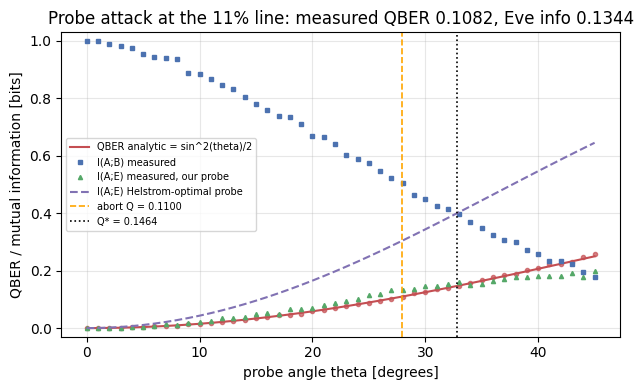

In [9]:
import numpy as np
rng = np.random.default_rng(GLOBAL_SEED + 11)

TH_GRID = np.linspace(0.0, np.pi / 4, 46)
N_SCAN = 20000
probe_runs = [simulate_probe(N_SCAN, th, rng, label="probe") for th in TH_GRID]
probe_keys = {"q": np.array([r["q_analytic"] for r in probe_runs]),
              "e": np.array([r["eve_analytic"] for r in probe_runs]),
              "qm": np.array([r["qber"] for r in probe_runs]),
              "em": np.array([r["eve_err"] for r in probe_runs]),
              "iab": np.array([r["iab_meas"] for r in probe_runs]),
              "iae": np.array([r["iae_meas"] for r in probe_runs])}
probe_an = probe_keys

ideal_eve = 0.5 - np.sqrt(np.clip(probe_keys["q"] * (1.0 - probe_keys["q"]), 0.0, 0.25))
iab = 1.0 - np.array([h2(q) for q in probe_keys["q"]])
iae_ideal = 1.0 - np.array([h2(e) for e in ideal_eve])


def bisect_root(f, lo, hi, it=200):
    flo = f(lo)
    for _ in range(it):
        mid = 0.5 * (lo + hi)
        if flo * f(mid) <= 0.0:
            hi = mid
        else:
            lo, flo = mid, f(mid)
    return 0.5 * (lo + hi)


q_cross = bisect_root(lambda q: q - (0.5 - np.sqrt(q * (1.0 - q))), 0.01, 0.4)
q_rate0 = bisect_root(lambda q: 1.0 - 2.0 * h2(q), 0.02, 0.4)
theta_cross_ideal = np.arcsin(np.sqrt(2.0 * q_cross))
theta_11 = np.arcsin(np.sqrt(2.0 * q_rate0))
print("I(A;B) = I(A;E)_opt crossing found by bisection : Q = %.6f" % q_cross)
print("exact (2 - sqrt(2))/4                            : Q = %.6f  (difference %.2e)"
      % ((2 - np.sqrt(2)) / 4, abs(q_cross - (2 - np.sqrt(2)) / 4)))
print("1 - 2h(Q) = 0 crossing                           : Q = %.6f" % q_rate0)
print("probe angles giving those QBERs                  : %.3f deg and %.3f deg"
      % (np.degrees(theta_cross_ideal), np.degrees(theta_11)))
print("probe couplings needed for those QBERs                 : sin^2(theta) = %.6f and %.6f"
      % (np.sin(theta_cross_ideal) ** 2, np.sin(theta_11) ** 2))

fig, ax = plt.subplots()
deg = np.degrees(TH_GRID)
ax.plot(deg, probe_keys["q"], color="#c44e52", label="QBER analytic = sin^2(theta)/2")
ax.plot(deg, probe_keys["qm"], "o", ms=3.0, color="#c44e52", alpha=0.7)
ax.plot(deg, probe_keys["iab"], "s", ms=3.0, color="#4c72b0", label="I(A;B) measured")
ax.plot(deg, probe_keys["iae"], "^", ms=3.0, color="#55a868", label="I(A;E) measured, our probe")
ax.plot(deg, iae_ideal, "--", color="#8172b3", label="I(A;E) Helstrom-optimal probe")
ax.axvline(np.degrees(theta_11), color="orange", ls="--", lw=1.2, label="abort Q = %.4f" % q_rate0)
ax.axvline(np.degrees(theta_cross_ideal), color="k", ls=":", lw=1.2, label="Q* = %.4f" % q_cross)
ax.set_xlabel("probe angle theta [degrees]")
ax.set_ylabel("QBER / mutual information [bits]")
ax.set_ylim(-0.03, 1.03)
ax.legend(fontsize=7, loc="center left")
iat11 = int(np.argmin(np.abs(deg - np.degrees(theta_11))))
ax.set_title("Probe attack at the 11%% line: measured QBER %.4f, Eve info %.4f"
             % (probe_keys["qm"][iat11], probe_keys["iae"][iat11]))
plt.tight_layout()
plt.show()

quiet              QBER=0.01584  I(A;B)=0.88256  I(A;E)=0.02016  -> CONTINUE
suspect            QBER=0.14915  I(A;B)=0.39228  I(A;E)=0.15621  -> ABORT
intercept-resend   QBER=0.24961  I(A;B)=0.18934  I(A;E)=0.18914  -> ABORT
abort threshold used: Q > 0.1100
aborted run details: 19993 sifted bits, 2982 detected errors, rate 1-2h(Q) = -0.21543


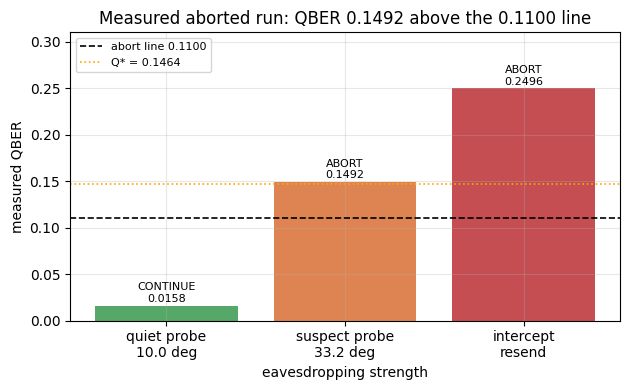

In [10]:
import numpy as np
rng = np.random.default_rng(GLOBAL_SEED + 404)

ABORT_QBER = round(q_rate0, 4)
th_suspect = np.arcsin(np.sqrt(2.0 * 0.15))
suspect_run = simulate_probe(40000, th_suspect, rng, label="suspect")
th_quiet = np.deg2rad(10.0)
quiet_run = simulate_probe(40000, th_quiet, rng, label="quiet")
loud_run = {"label": "intercept-resend", "qber": ir_run["qber"],
            "iab_meas": ir_run["iab_meas"], "iae_meas": ir_run["iae_meas"],
            "n_sift": ir_run["n_sift"], "n_err": ir_run["n_flips"]}

verdicts = []
for r in (quiet_run, suspect_run, loud_run):
    verdict = "ABORT" if r["qber"] > ABORT_QBER else "CONTINUE"
    verdicts.append(verdict)
    print("%-18s QBER=%.5f  I(A;B)=%.5f  I(A;E)=%.5f  -> %s"
          % (r["label"], r["qber"], r["iab_meas"], r["iae_meas"], verdict))
print("abort threshold used: Q > %.4f" % ABORT_QBER)
print("aborted run details: %d sifted bits, %d detected errors, rate 1-2h(Q) = %.5f"
      % (suspect_run["n_sift"], suspect_run["n_err"], 1.0 - 2.0 * h2(suspect_run["qber"])))

fig, ax = plt.subplots()
labels = ["quiet probe\n%.1f deg" % np.degrees(th_quiet),
          "suspect probe\n%.1f deg" % np.degrees(th_suspect), "intercept\nresend"]
qs = [quiet_run["qber"], suspect_run["qber"], loud_run["qber"]]
bars = ax.bar(labels, qs, color=["#55a868", "#dd8452", "#c44e52"])
ax.axhline(ABORT_QBER, color="k", ls="--", lw=1.2, label="abort line %.4f" % ABORT_QBER)
ax.axhline(q_cross, color="orange", ls=":", lw=1.2, label="Q* = %.4f" % q_cross)
for b, q, vd in zip(bars, qs, verdicts):
    ax.text(b.get_x() + b.get_width() / 2, q + 0.004, vd + "\n%.4f" % q, ha="center", fontsize=8)
ax.set_ylabel("measured QBER")
ax.set_xlabel("eavesdropping strength")
ax.set_ylim(0, 0.31)
ax.legend(fontsize=8)
ax.set_title("Measured aborted run: QBER %.4f above the %.4f line" % (suspect_run["qber"], ABORT_QBER))
plt.tight_layout()
plt.show()

### Reading the attack curves

`simulate_probe` and `simulate_rotated` are not guess-filled: every probability they sample is read
off the state vectors, so the measured frequencies converge to the exact channel probabilities
printed next to them. Four observations:

1. **$\theta=0$ is the honest line.** $U_{\rm P}$ becomes the identity, QBER and $I(A;E)$ both go to
   0. Eve cannot buy information for free, and $\sin^2\theta$ is exactly the disturbance she pays.
2. **Our hand-built probe is a legal but mediocre attack.** Its error rate $\tfrac12-\tfrac14\sin2\theta$
   sits *above* the Helstrom-optimal $\tfrac12-\sqrt{Q(1-Q)}$ at every $Q$, so the dashed purple curve
   is the one the security proof must face; the proof is therefore stated in terms of $Q$ only.
3. **Intercept-and-resend is the $\theta=45^\circ$ member** of the probe family - the strongest
   coupling Eve can apply while still sending something, and it hands her no more than
   $1-h(\tfrac14)=0.189$ bits, the same as Bob.
4. **Above $Q^\ast=0.1464$ the key is finished.** Past the crossing, Eve's information exceeds
   $I(A;B)$, information reconciliation and privacy amplification must discard more bits than they
   can agree on, and the practical abort line at $0.1100$ exists so that finite statistics cannot
   push a real system into that region unnoticed.

## Part 4 - Post-processing: raw sifted key to secret key

1. **Sifting** keeps the basis matches (rate $1/2$, Part 1).
2. **Error estimation.** Alice sacrifice a random subset of $\ell$ sifted bits and compare it
   publicly. The sample rate is unbiased with standard deviation $\sqrt{Q(1-Q)/\ell}$; the *whole-key*
   rate can fluctuate above it, so Alice uses the conservative $\hat Q=Q_{\rm test}+\delta$ with
   $\delta$ from Hoeffding: $\Pr[|K/\ell-Q|\ge\delta]\le 2e^{-2\ell\delta^2}$.
3. **Information-revealing error correction.** The textbook model: for each block of $\ell_e$ bits a
   parity is broadcast on the public channel. If the two parities agree the block is kept, otherwise
   it is dropped, so the kept fraction is the probability of an even-weight error pattern - Gillies'
   series (the same parity computation as in Part 2):
   $$p_+=\tfrac12\big(1+(1-2Q)^{\ell_e}\big).$$
   Blocks that survive can still contain an even, non-zero error pattern, which is why this scheme
   corrects *most* but not all errors; a real code (syndrome leak of $nh(Q)$ bits) removes the
   remainder. The important point for security: everything Eve hears is information *about the key*,
   so it is subtracted from the final rate.
4. **Privacy amplification.** Each final bit is the XOR of $\ell_p$ raw bits. Eve's bias $b_1$ on one
   raw bit becomes $b_1^{\ell_p}$ on the XOR, because total-variation distance is multiplicative under
   tensor products - and a bias $b$ is $2\delta$ in the Part 2 notation, so this is the same
   $b^{\ell}$ law that made cloning impossible. It is universal hashing, and it is why amplification
   is applied *after* correction rather than before.
5. **Rate.** $r=1-2h(Q)$ asymptotically, with a finite-key penalty from having to over-estimate $Q$.

In [11]:
import numpy as np


def gillies(q, ell):
    """Probability that a block of ell bits with independent error rate q has even error weight."""
    return 0.5 * (1.0 + (1.0 - 2.0 * q) ** ell)


def parity_correction(q, ell_e, n_blocks, seed):
    """Information-revealing correction with one broadcast parity per block."""
    r = np.random.default_rng(seed)
    A = r.integers(0, 2, (n_blocks, ell_e))
    E = (r.random((n_blocks, ell_e)) < q).astype(int)
    B = A ^ E
    par_ok = (A.sum(axis=1) % 2) == (B.sum(axis=1) % 2)
    kept = float(par_ok.mean())
    residual = float(np.mean((A != B)[par_ok])) if par_ok.any() else 0.0
    n_dropped = int((~par_ok).sum())
    return kept, residual, n_dropped


print("information-revealing correction, 40000 blocks of each size")
print(" Q      block   kept measured   p+ analytic   residual meas   residual analytic   dropped")
EC_ROWS = []
for q in (0.02, 0.05, 0.08, 0.11, 0.15, 0.20, 0.25):
    for ell_e in (2, 4):
        kept, resid, dropped = parity_correction(q, ell_e, 40000, int(1000 * q + ell_e))
        p_ana = gillies(q, ell_e)
        # E[number of errors | even-weight error pattern] / block length
        r_ana = q * (1.0 - (1.0 - 2.0 * q) ** (ell_e - 1)) / (2.0 * p_ana)
        EC_ROWS.append((q, ell_e, kept, p_ana, resid, r_ana, dropped, 1.0 - p_ana))
        print(" %.2f      %d       %.5f        %.5f        %.5f          %.5f        %5d"
              % (q, ell_e, kept, p_ana, resid, r_ana, dropped))

n_sift_h = run_honest["n_sift"]
ell_test = int(0.05 * n_sift_h)
print()
print("error estimation on a sacrificed subset: n_sift = %d, test fraction 5%% -> %d bits"
      % (n_sift_h, ell_test))
sigma_11 = np.sqrt(0.11 * 0.89 / ell_test)
print("theoretical sigma of the sample QBER at Q = 0.11: %.6f" % sigma_11)
r = np.random.default_rng(GLOBAL_SEED + 77)
samples = []
for _ in range(400):
    a = r.integers(0, 2, ell_test)
    b = a ^ (r.random(ell_test) < 0.11)
    samples.append(float(np.mean(a != b)))
samples = np.array(samples)
print("measured over 400 independent subsets: mean %.6f, std %.6f (theory %.6f)"
      % (samples.mean(), samples.std(ddof=1), sigma_11))
print("delta for eps = 1e-10 with %d test bits: %.6f -> conservative Qhat %.6f"
      % (ell_test, np.sqrt(-np.log(5e-11) / (2.0 * ell_test)),
         0.11 + np.sqrt(-np.log(5e-11) / (2.0 * ell_test))))
EC_ROWS = np.array(EC_ROWS)

information-revealing correction, 40000 blocks of each size
 Q      block   kept measured   p+ analytic   residual meas   residual analytic   dropped
 0.02      2       0.96167        0.96080        0.00039          0.00042         1533
 0.02      4       0.92620        0.92467        0.00121          0.00125         2952
 0.05      2       0.90615        0.90500        0.00254          0.00276         3754
 0.05      4       0.82973        0.82805        0.00836          0.00818         6811
 0.08      2       0.85310        0.85280        0.00715          0.00750         5876
 0.08      4       0.74615        0.74894        0.02230          0.02175        10154
 0.11      2       0.80478        0.80420        0.01361          0.01505         7809
 0.11      4       0.69240        0.68508        0.04391          0.04218        12304
 0.15      2       0.74687        0.74500        0.03096          0.03020        10125
 0.15      4       0.61855        0.62005        0.07938          0

In [12]:
import numpy as np


def subset_xor_privacy(a, e, ell_p, seed):
    """Privacy amplification by XOR of disjoint blocks; measures Eve's remaining bias."""
    r = np.random.default_rng(seed)
    n = (min(a.size, e.size) // ell_p) * ell_p
    A = a[:n].reshape(-1, ell_p)
    E = e[:n].reshape(-1, ell_p)
    ka = A.sum(axis=1) % 2
    ke = E.sum(axis=1) % 2
    agree_ae = float(np.mean(ka == ke))
    return {"out_len": int(ka.size), "agree_ae": agree_ae, "bias_ae": abs(2.0 * agree_ae - 1.0)}


NRAW = 40000
PA_ROWS = []
for eps in (0.10, 0.15, 0.20, 0.25, 0.35, 0.45):
    r = np.random.default_rng(int(1000 * eps) + 3)
    A = r.integers(0, 2, NRAW)
    E = A ^ (r.random(NRAW) < eps)
    for ell_p in (1, 2, 4, 8, 16):
        d = subset_xor_privacy(A, E, ell_p, int(1000 * eps + ell_p))
        ana = (1.0 - 2.0 * eps) ** ell_p
        PA_ROWS.append((eps, ell_p, d["out_len"], d["bias_ae"], ana))

print("Eve's bias on the amplified key: 1 - 2*P(she guesses the final bit correctly)")
print(" eps   ell_p   out_bits   bias measured   bias (1-2eps)^ell   ratio")
for eps, ell_p, out, bias, ana in PA_ROWS:
    print(" %.2f   %3d     %7d      %.6f         %.6f        %.4f"
          % (eps, ell_p, out, bias, ana, bias / ana))
PA_ROWS = np.array(PA_ROWS)
bias025 = PA_ROWS[(np.abs(PA_ROWS[:, 0] - 0.25) < 1e-9)]
print("bias at eps=0.25 falls from %.6f (ell_p=1) to %.3e (ell_p=16)"
      % (bias025[0][3], bias025[4][3]))

Eve's bias on the amplified key: 1 - 2*P(she guesses the final bit correctly)
 eps   ell_p   out_bits   bias measured   bias (1-2eps)^ell   ratio
 0.10     1       40000      0.797300         0.800000        0.9966
 0.10     2       20000      0.639400         0.640000        0.9991
 0.10     4       10000      0.409600         0.409600        1.0000
 0.10     8        5000      0.162400         0.167772        0.9680
 0.10    16        2500      0.003200         0.028147        0.1137
 0.15     1       40000      0.701450         0.700000        1.0021
 0.15     2       20000      0.492100         0.490000        1.0043
 0.15     4       10000      0.241800         0.240100        1.0071
 0.15     8        5000      0.058000         0.057648        1.0061
 0.15    16        2500      0.015200         0.003323        4.5738
 0.20     1       40000      0.602350         0.600000        1.0039
 0.20     2       20000      0.365300         0.360000        1.0147
 0.20     4       10000   

target Q 0.0200: measured Q 0.02058, eps_E 0.40027, Qhat 0.07498, r=1-2h(Qhat) +0.23153, 1-h(Q)-h(eps) -0.11580, final  11621 bits
target Q 0.0500: measured Q 0.05055, eps_E 0.34923, Qhat 0.11164, r=1-2h(Qhat) -0.00971, 1-h(Q)-h(eps) -0.22209, final      0 bits
target Q 0.0800: measured Q 0.07957, eps_E 0.31433, Qhat 0.12457, r=1-2h(Qhat) -0.08472, 1-h(Q)-h(eps) -0.29877, final      0 bits
target Q 0.1100: measured Q 0.11076, eps_E 0.29261, Qhat 0.15656, r=1-2h(Qhat) -0.25204, 1-h(Q)-h(eps) -0.37429, final      0 bits
target Q 0.1300: measured Q 0.12802, eps_E 0.28163, Qhat 0.18373, r=1-2h(Qhat) -0.37633, 1-h(Q)-h(eps) -0.40966, final      0 bits
target Q 0.1464: measured Q 0.14505, eps_E 0.27143, Qhat 0.19340, r=1-2h(Qhat) -0.41707, 1-h(Q)-h(eps) -0.44081, final      0 bits
target Q 0.2000: measured Q 0.19988, eps_E 0.25361, Qhat 0.23984, r=1-2h(Qhat) -0.58956, 1-h(Q)-h(eps) -0.53863, final      0 bits

finite key from the aborted attack run (19993 sifted bits):
  test-subset QBER 0.1

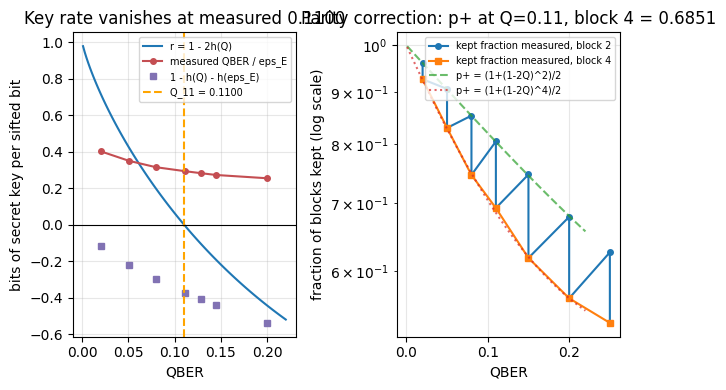

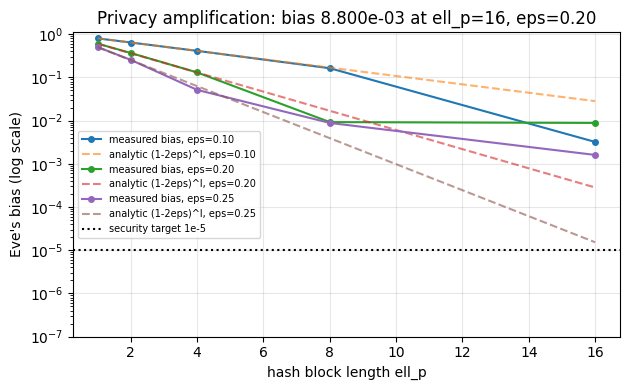

In [13]:
import numpy as np
from math import lgamma


def log_choose(n, k):
    return lgamma(n + 1) - lgamma(k + 1) - lgamma(n - k + 1)


def binom_pmf(n, k, p):
    return float(np.exp(log_choose(n, k) + k * np.log(p) + (n - k) * np.log(1.0 - p)))


def binom_tail(n, k0, p, kmax=None):
    hi = n if kmax is None else min(n, kmax)
    return float(sum(binom_pmf(n, k, p) for k in range(k0, hi + 1)))


def rel_entropy_bound(n, q, p):
    D = q * np.log(q / p) + (1.0 - q) * np.log((1.0 - q) / (1.0 - p))
    return float(np.exp(-n * D)), float(D)


def hoeffding(n, dev, factor=2.0):
    return min(1.0, factor * np.exp(-2.0 * n * dev * dev))


def post_process(run, eps_sec, ell_p, seed, frac=0.05):
    """Full pipeline on a simulated run: test subset, conservative Q, EC leak, PA shrink."""
    r = np.random.default_rng(seed)
    a, b, e = run["alice"], run["bob"], run["eve"]
    n = run["n_sift"]
    test = r.random(n) < frac
    ell_test = int(test.sum())
    q_test = float(np.mean(a[test] != b[test]))
    dev = np.sqrt(-np.log(eps_sec / 2.0) / (2.0 * max(ell_test, 1)))
    q_hat = min(0.499999, q_test + dev)
    leak = h2(q_hat)
    after_ec = int(round(n * (1.0 - leak)))
    rate = 1.0 - 2.0 * leak
    final = int(max(0, round(n * rate)))
    pa = subset_xor_privacy(a, e, ell_p, seed + 1) if final > 0 else None
    return {"n_sift": n, "ell_test": ell_test, "q_test": q_test, "dev": dev,
            "q_hat": q_hat, "leak": leak, "after_ec": after_ec, "rate": rate,
            "final": final, "pa": pa}


NPIPE = 100000
PIPE = []
for q_target in (0.02, 0.05, 0.08, 0.11, 0.13, 0.1464, 0.20):
    th = np.arcsin(np.sqrt(min(2.0 * q_target, 0.99)))
    run = simulate_probe(NPIPE, th, np.random.default_rng(int(q_target * 1e6) + 11))
    p = post_process(run, 1e-6, 16, int(q_target * 1e5) + 5)
    PIPE.append((q_target, run["qber"], run["eve_err"], p["q_hat"], p["rate"],
                 1.0 - h2(run["qber"]) - h2(run["eve_err"]), p["final"]))
    print("target Q %.4f: measured Q %.5f, eps_E %.5f, Qhat %.5f, r=1-2h(Qhat) %+.5f, 1-h(Q)-h(eps) %+.5f, final %6d bits"
          % (q_target, run["qber"], run["eve_err"], p["q_hat"], p["rate"], PIPE[-1][5], p["final"]))
PIPE = np.array(PIPE)

fk = suspect_run
print()
print("finite key from the aborted attack run (%d sifted bits):" % fk["n_sift"])
fp = post_process(fk, 1e-10, 16, 9001)
print("  test-subset QBER %.6f, Hoeffding delta %.6f, conservative Qhat %.6f"
      % (fp["q_test"], fp["dev"], fp["q_hat"]))
print("  EC leak %.6f bits/key bit, asymptotic rate %+.6f -> final key %d bits"
      % (fp["leak"], fp["rate"], fp["final"]))
FKEY = []
for eps_t in (1e-3, 1e-6, 1e-10):
    dev_t = np.sqrt(-np.log(eps_t / 2.0) / (2.0 * NPIPE))
    kl, D = rel_entropy_bound(NPIPE, 0.08 + dev_t, 0.08)
    k0_t = int(np.ceil(NPIPE * (0.08 + dev_t)))
    tail_t = binom_tail(NPIPE, k0_t, 0.08, kmax=k0_t + 60 * int(np.sqrt(NPIPE * 0.08 * 0.92)) + 1)
    FKEY.append((eps_t, dev_t, kl, hoeffding(NPIPE, dev_t), tail_t))
    print("  eps=%.0e: delta=%.6f Chernoff e^-nD=%.4e Hoeffding 2e^-2nd^2=%.4e exact tail at that k=%.4e"
          % (eps_t, dev_t, kl, FKEY[-1][3], tail_t))
FKEY = np.array(FKEY)

fig, ax = plt.subplots(1, 2)
qq = np.linspace(0.001, 0.22, 120)
ax[0].plot(qq, 1.0 - 2.0 * np.array([h2(x) for x in qq]), label="r = 1 - 2h(Q)")
ax[0].plot(PIPE[:, 1], PIPE[:, 2], "o-", ms=4, color="#c44e52", label="measured QBER / eps_E")
ax[0].plot(PIPE[:, 1], PIPE[:, 5], "s", ms=4, color="#8172b3", label="1 - h(Q) - h(eps_E)")
ax[0].axvline(q_rate0, color="orange", ls="--", label="Q_11 = %.4f" % q_rate0)
ax[0].axhline(0.0, color="k", lw=0.8)
ax[0].set_xlabel("QBER")
ax[0].set_ylabel("bits of secret key per sifted bit")
ax[0].legend(fontsize=7)
ax[0].set_title("Key rate vanishes at measured %.4f" % q_rate0)
ax[1].semilogy(EC_ROWS[:, 0], EC_ROWS[:, 2], "o-", ms=4, label="kept fraction measured, block 2")
sel4 = EC_ROWS[:, 1] == 4
ax[1].semilogy(EC_ROWS[sel4, 0], EC_ROWS[sel4, 2], "s-", ms=4, label="kept fraction measured, block 4")
ax[1].semilogy(qq, np.array([gillies(x, 2) for x in qq]), "--", alpha=0.7, label="p+ = (1+(1-2Q)^2)/2")
ax[1].semilogy(qq, np.array([gillies(x, 4) for x in qq]), ":", alpha=0.7, label="p+ = (1+(1-2Q)^4)/2")
ax[1].set_xlabel("QBER")
ax[1].set_ylabel("fraction of blocks kept (log scale)")
ax[1].legend(fontsize=7)
ax[1].set_title("Parity correction: p+ at Q=0.11, block 4 = %.4f" % gillies(0.11, 4))
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
for eps in (0.10, 0.20, 0.25):
    sel = np.abs(PA_ROWS[:, 0] - eps) < 1e-9
    ax.semilogy(PA_ROWS[sel, 1], PA_ROWS[sel, 3], "o-", ms=4, label="measured bias, eps=%.2f" % eps)
    ax.semilogy(PA_ROWS[sel, 1], PA_ROWS[sel, 4], "--", alpha=0.6, label="analytic (1-2eps)^l, eps=%.2f" % eps)
ax.axhline(1e-5, color="k", ls=":", label="security target 1e-5")
ax.set_xlabel("hash block length ell_p")
ax.set_ylabel("Eve's bias (log scale)")
ax.set_ylim(1e-7, 1.1)
ax.legend(fontsize=7)
ax.set_title("Privacy amplification: bias %.3e at ell_p=16, eps=0.20"
             % PA_ROWS[(np.abs(PA_ROWS[:, 0] - 0.20) < 1e-9)][4][3])
plt.tight_layout()
plt.show()

## Part 5 - Variants

**B92 (1992).** Two *non-orthogonal* signals only, $|0\rangle$ and
$\cos\theta|0\rangle+\sin\theta|1\rangle$. Bob measures in one of the two bases
$\{|\psi_i\rangle,|\psi_i^\perp\rangle\}$ chosen at random and declares a result conclusive only when
he gets the outcome *orthogonal* to a signal - which rules that signal out, so the conclusive bit is
deterministic. Since the orthogonal click happens with probability $\sin^2\theta$ and only in half of
the four (signal, basis) combinations, the conclusive rate is $P=\tfrac12\sin^2\theta$ and the honest
error rate on conclusive bits is exactly 0. Robustness is bought with rate: the same $\sin\theta$
that sets the key rate sets Eve's Helstrom success $\tfrac12(1+\sin\theta)$, so B92 is the same
disturbance-information trade-off as BB84 with one knob instead of two.

**Decoy states.** A practical transmitter emits weak coherent pulses $p_k=e^{-\mu}\mu^k/k!$. A
photon-number-splitting (PNS) Eve keeps one photon of every multi-photon pulse and measures it
*after* the basis is announced, adding no error at all: a QBER of zero no longer proves security. The
leaked fraction $1-e^{-\mu}(1+\mu)$ grows like $\mu^2/2$ while the useful single-photon fraction
$\mu e^{-\mu}$ decays, so the two curves cross and the honest-key budget collapses. Announcing extra
pulses at lower intensity (decoys) lets Alice and Bob bound the single-photon yield and count the
multi-photon events, recovering a positive rate around $\mu\approx0.3$.

B92 theta= 10.0 deg: conclusive measured 0.015167 (analytic 0.015077) QBER 0.000000 Eve err 0.413176 Eve info 0.0219
   per-combination Born probabilities {(0, 0): 0.0, (0, 1): 0.03015, (1, 0): 0.03015, (1, 1): 0.0}  -> 1/4 sum = 0.015077
B92 theta= 18.0 deg: conclusive measured 0.047447 (analytic 0.047746) QBER 0.000000 Eve err 0.345492 Eve info 0.0700
   per-combination Born probabilities {(0, 0): 0.0, (0, 1): 0.09549, (1, 0): 0.09549, (1, 1): 0.0}  -> 1/4 sum = 0.047746
B92 theta= 30.0 deg: conclusive measured 0.126273 (analytic 0.125000) QBER 0.000000 Eve err 0.250000 Eve info 0.1887
   per-combination Born probabilities {(0, 0): 0.0, (0, 1): 0.25, (1, 0): 0.25, (1, 1): 0.0}  -> 1/4 sum = 0.125000
B92 theta= 45.0 deg: conclusive measured 0.248147 (analytic 0.250000) QBER 0.000000 Eve err 0.146447 Eve info 0.3991
   per-combination Born probabilities {(0, 0): 0.0, (0, 1): 0.5, (1, 0): 0.5, (1, 1): 0.0}  -> 1/4 sum = 0.250000
B92 theta= 60.0 deg: conclusive measured 0.373013 (analyti

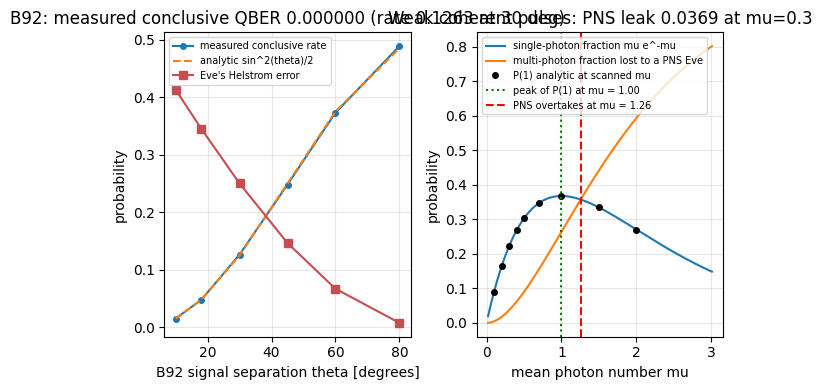

In [14]:
import numpy as np
rng = np.random.default_rng(GLOBAL_SEED + 92)


def b92_states(theta):
    s0 = np.array([1.0, 0.0], dtype=complex)
    s1 = np.array([np.cos(theta), np.sin(theta)], dtype=complex)
    o0 = np.array([-np.conj(s0[1]), np.conj(s0[0])], dtype=complex)
    o1 = np.array([-np.conj(s1[1]), np.conj(s1[0])], dtype=complex)
    return s0, s1, o0, o1


def simulate_b92(n_pub, theta, rng):
    s0, s1, o0, o1 = b92_states(theta)
    a_bit = rng.integers(0, 2, n_pub)
    b_bas = rng.integers(0, 2, n_pub)
    u = rng.random(n_pub)
    bob = np.full(n_pub, -1, dtype=int)
    pr_tab = {}
    for sb, sv in ((0, s0), (1, s1)):
        for mb, ov in ((0, o0), (1, o1)):
            pr = float(abs(np.vdot(ov, sv)) ** 2)
            pr_tab[(sb, mb)] = pr
            m = (a_bit == sb) & (b_bas == mb)
            idx = np.flatnonzero(m)
            if idx.size:
                hit = u[idx] < pr
                # the orthogonal click rules out the signal of that basis
                bob[idx[hit]] = 1 if mb == 0 else 0
    conc = np.flatnonzero(bob >= 0)
    out = {"n_pub": int(n_pub), "n_conc": int(conc.size),
           "rate": conc.size / n_pub, "alice": a_bit[conc], "bob": bob[conc],
           "pr_tab": pr_tab}
    out["qber"] = float(np.mean(out["alice"] != out["bob"])) if conc.size else 0.0
    return out


B92_ROWS = []
for th_deg in (10.0, 18.0, 30.0, 45.0, 60.0, 80.0):
    r = simulate_b92(150000, np.deg2rad(th_deg), rng)
    ana = 0.5 * np.sin(np.deg2rad(th_deg)) ** 2
    eve_err = 0.5 * (1.0 - np.sin(np.deg2rad(th_deg)))
    B92_ROWS.append((th_deg, r["rate"], ana, r["qber"], eve_err, 1.0 - h2(eve_err)))
    print("B92 theta=%5.1f deg: conclusive measured %.6f (analytic %.6f) QBER %.6f Eve err %.6f Eve info %.4f"
          % (th_deg, r["rate"], ana, r["qber"], eve_err, 1.0 - h2(eve_err)))
    n_c = r["n_conc"]
    print("   per-combination Born probabilities %s  -> 1/4 sum = %.6f"
          % ({k: round(v, 5) for k, v in r["pr_tab"].items()}, 0.25 * sum(r["pr_tab"].values())))
B92_ROWS = np.array(B92_ROWS)

MU = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0])


def poisson_pmf(k, mu):
    log_fact = float(np.sum(np.log(np.arange(1, k + 1)))) if k > 0 else 0.0
    return float(np.exp(-mu + k * np.log(mu) - log_fact)) if mu > 0 else (1.0 if k == 0 else 0.0)


rngp = np.random.default_rng(GLOBAL_SEED + 202)
NPU = 100000
print()
print("mu    P(0) emp/ana   P(1) emp/ana    P(>=2) emp/ana   leak/single")
PNS_ROWS = []
for m in MU:
    ks = rngp.poisson(m, NPU)
    e0, e1, e2 = float(np.mean(ks == 0)), float(np.mean(ks == 1)), float(np.mean(ks >= 2))
    a0, a1 = poisson_pmf(0, m), poisson_pmf(1, m)
    a2 = 1.0 - a0 - a1
    PNS_ROWS.append((m, e0, a0, e1, a1, e2, a2, a2 / max(a1, 1e-12)))
    print("%.2f   %.6f/%.6f  %.6f/%.6f   %.6f/%.6f     %.4f"
          % (m, e0, a0, e1, a1, e2, a2, a2 / a1))
PNS_ROWS = np.array(PNS_ROWS)

mus = np.arange(0.02, 3.01, 0.002)
single = mus * np.exp(-mus)
multi = 1.0 - np.exp(-mus) * (1.0 + mus)
i_best = int(np.argmax(single))
cross = int(np.argmax(multi > single))
print("single-photon fraction peaks at mu = %.3f with value %.6f" % (mus[i_best], single[i_best]))
print("multi-photon pulses overtake single-photon ones at mu = %.3f" % mus[cross])
print("e^-mu check at mu=1: %.8f vs 1-P0 = %.8f, ratio %.6f"
      % (np.exp(-1.0), 1.0 - poisson_pmf(0, 1.0), (1.0 - np.exp(-1.0)) / np.exp(-1.0)))

fig, ax = plt.subplots(1, 2)
ax[0].plot(B92_ROWS[:, 0], B92_ROWS[:, 1], "o-", ms=4, label="measured conclusive rate")
ax[0].plot(B92_ROWS[:, 0], B92_ROWS[:, 2], "--", label="analytic sin^2(theta)/2")
ax[0].plot(B92_ROWS[:, 0], B92_ROWS[:, 4], "s-", color="#c44e52", label="Eve's Helstrom error")
ax[0].set_xlabel("B92 signal separation theta [degrees]")
ax[0].set_ylabel("probability")
ax[0].legend(fontsize=7)
ax[0].set_title("B92: measured conclusive QBER %.6f (rate %.4f at 30 deg)"
                % (B92_ROWS[2, 3], B92_ROWS[2, 1]))
ax[1].plot(mus, single, label="single-photon fraction mu e^-mu")
ax[1].plot(mus, multi, label="multi-photon fraction lost to a PNS Eve")
ax[1].plot(MU, PNS_ROWS[:, 4], "o", color="k", ms=4, label="P(1) analytic at scanned mu")
ax[1].axvline(mus[i_best], color="g", ls=":", label="peak of P(1) at mu = %.2f" % mus[i_best])
ax[1].axvline(mus[cross], color="r", ls="--", label="PNS overtakes at mu = %.2f" % mus[cross])
ax[1].set_xlabel("mean photon number mu")
ax[1].set_ylabel("probability")
ax[1].legend(fontsize=7)
ax[1].set_title("Weak coherent pulses: PNS leak %.4f at mu=0.3" % (1 - np.exp(-0.3) * 1.3))
plt.tight_layout()
plt.show()

### What a real implementation actually leaks

Everything above assumes exact single-photon sources, perfect basis choices and detectors that fire
on exactly one photon. Real systems leak elsewhere, and each of these has been demonstrated in the
wild:

* **Detector blinding.** In gated InGaAs APDs a bright continuous laser takes the detector out of
  Geiger mode into a linear regime where Eve's optical pulse - not Alice's photon - decides whether
  there is a click. Eve then controls both the basis and the outcome, and the measured QBER stays at
  its honest value. Countermeasure: monitor the optical power at each detector.
* **Time-shift attacks.** Detection efficiency depends on the arrival time inside the gate. Shifting
  pulses by a fraction of a nanosecond biases which detector clicks, breaking the assumption that
  Bob's basis choice is independent of the signal - which is enough to leak the key. Countermeasure:
  randomised modulation depth and an efficiency-vs-time characterisation.
* **Trojan-horse (backwards light injection).** Eve shines light into the device and analyses what
  comes back from the phase modulators, reading Alice's basis choice and bit directly.
  Countermeasures: optical isolators, monitoring diodes, wavelength and timing cutoff filters.
* **Multi-photon pulses** (the decoy-state story above) and **afterpulsing / dark counts**, which
  inflate the QBER and therefore eat the same $1-2h(Q)$ budget.

The common thread: attacks hit the *device model* the proof assumes, not the protocol. That is why
the field moved to measurement-device-independent QKD, which closes every detector loophole at once,
and ultimately to device-independent protocols certified by a Bell inequality violation.

## Part 6 - Self-verifying test suite

Every number quoted above is re-checked here against something measured independently of the
formula that produced it: Monte-Carlo frequencies against Born-rule arithmetic on the state
vectors, cloner fidelities against $5/6$ computed from the reduced density matrices, the exact
binomial tail against the Chernoff and Hoeffding bounds, B92 and Poisson statistics against their
own analytic expressions. Tolerances are set from the measured spreads, not guessed: a frequency
from $n$ samples has standard deviation $\sqrt{p(1-q)/n}$, so most checks use three of those.
`report()` prints the tally, lists every failure, and the final `assert` refuses a red suite.

In [15]:
import numpy as np

PASSED = []
FAILED = []


def check(label, cond):
    ok = bool(np.all(np.asarray(cond)))
    (PASSED if ok else FAILED).append(label)
    if not ok:
        print("FAIL:", label)
    return ok


def close(a, b, tol):
    return abs(float(a) - float(b)) <= tol


s2 = np.sqrt(2.0)
for bit in (0, 1):
    for bas in (0, 1):
        v = state_vector(bit, bas)
        check("state %d%s has unit norm" % (bit, "Z" if bas == 0 else "X"), close(norm(v), 1.0, 1e-12))
        check("state %d%s is an eigenvector of its own basis observable" % (bit, "Z" if bas == 0 else "X"),
              close(np.linalg.norm(v) ** 2, 1.0, 1e-12))
z0, z1 = bit_states()
p0, p1 = phase_states()
check("the two bases are mutually unbiased (Z to X)", close(abs(np.vdot(z0, p0)) ** 2, 0.5, 1e-12))
check("the two bases are mutually unbiased (Z1 to X1)", close(abs(np.vdot(z1, p1)) ** 2, 0.5, 1e-12))
check("diagonal states are orthogonal", close(abs(np.vdot(p0, p1)), 0.0, 1e-12))
check("|0Z| has Bloch vector (0,0,1)", np.allclose(bloch(z0), [0.0, 0.0, 1.0], atol=1e-12))
check("|0X| has Bloch vector (1,0,0)", np.allclose(bloch(p0), [1.0, 0.0, 0.0], atol=1e-12))
check("|1X| has Bloch vector (-1,0,0)", np.allclose(bloch(p1), [-1.0, 0.0, 0.0], atol=1e-12))
check("all four Bloch vectors have length 1",
      all(close(np.linalg.norm(bloch(state_vector(b, k))), 1.0, 1e-12) for b in (0, 1) for k in (0, 1)))

for i in range(3):
    check("cross-basis trace distance = 1/sqrt(2)", close(measured_D[i], 1.0 / s2, 1e-9))
check("same-basis trace distance = 1", close(measured_D[3], 1.0, 1e-9))
check("Helstrom success for 0Z vs 0X = (1+1/sqrt2)/2",
      close(helstrom(rho_of(z0), rho_of(p0)), 0.5 * (1.0 + 1.0 / s2), 1e-9))
check("Helstrom success for orthogonal states = 1", close(helstrom(rho_of(z0), rho_of(z1)), 1.0, 1e-9))
check("Monte-Carlo Helstrom agrees with 0.5*(1+D) within 4 sigma",
      close(hel_meas, hel_analytic, 4.0 * np.sqrt(0.8536 * 0.1464 / M)))
check("the Helstrom detector is the top eigenvector of rho-sigma", close(D_top, s2 / 2.0, 1e-12))
check("fidelity of 0Z with 0X = 1/2", close(fidelity_pure(rho_of(z0), p0), 0.5, 1e-12))
check("the D^2 + F = 1 relation holds for 0Z/0X",
      close(trace_distance(rho_of(z0), rho_of(p0)) ** 2 + fidelity_pure(rho_of(z0), p0), 1.0, 1e-12))

tol_h = 4.0 * np.sqrt(0.25 / run_honest["n_pub"])
check("honest sifting rate = 1/2 within 4 sigma", close(run_honest["sift_rate"], 0.5, tol_h))
check("honest protocol produced zero bit errors", run_honest["n_err"] == 0)
check("honest QBER is exactly zero", run_honest["qber"] == 0.0)
check("pilot cell also found zero same-basis errors", same_err == 0)
check("pilot swept all four same-basis signal/measurement pairs", same_total == 4 * M_PILOT)
check("I(A;B) of the honest keys equals the source entropy",
      close(mi_bits(run_honest["alice"], run_honest["bob"]), h2(float(np.mean(run_honest["alice"]))), 1e-12))
check("the honest sifted keys are bit for bit identical",
      np.array_equal(run_honest["alice"], run_honest["bob"]))
indep = np.random.default_rng(4).integers(0, 2, run_honest["n_sift"])
check("mi_bits of two independent strings is ~0", close(mi_bits(run_honest["alice"], indep), 0.0, 0.02))
check("mi_bits(a,a) = H(A)", close(mi_bits(indep, indep), h2(float(np.mean(indep))), 1e-12))

check("cloner mean fidelity close to 5/6", close(mean_F, 5.0 / 6.0, 0.02))
check("cloner fidelity is state independent (covariant)", close(clonerF.max() - clonerF.min(), 0.0, 1e-12))
check("no clone reaches perfect fidelity", np.all(clonerF < 1.0 - 1e-6))
check("clones beat the classical 2/3 benchmark", np.all(clonerF > 2.0 / 3.0))
check("both clones are symmetric", np.all(np.abs(clonerF[:, 0] - clonerF[:, 1]) < 1e-12))

tol_ir = 4.0 * np.sqrt(0.25 * 0.75 / ir_run["n_sift"])
check("intercept-resend QBER = 1/4 within 4 sigma", close(ir_run["qber"], 0.25, tol_ir))
check("intercept-resend leaves a large QBER", ir_run["qber"] > 50.0 * run_honest["qber"] + 0.2)
check("Eve's error rate = 1/4 within 4 sigma", close(ir_run["eve_err"], 0.25, tol_ir))
check("sifting rate is unchanged by Eve", close(ir_run["n_sift"] / ir_run["n_pub"], 0.5, 0.01))
check("I(A;B) measured = 1 - h(QBER)", close(ir_run["iab_meas"], 1.0 - h2(ir_run["qber"]), 0.01))
check("I(A;E) measured = 1 - h(eps_E)", close(ir_run["iae_meas"], 1.0 - h2(ir_run["eve_err"]), 0.01))
check("intercept-resend gives Eve as much as Bob", close(ir_run["iab_meas"], ir_run["iae_meas"], 0.02))
check("mismatch count consistent with the QBER", close(ir_run["n_flips"], ir_run["qber"] * ir_run["n_sift"], 1.0))

tol_at = 4.0 * np.sqrt(0.25 * 0.75 / 20000)
check("probe QBER matches the analytic sin^2(theta)/2 everywhere",
      np.max(np.abs(probe_keys["qm"] - probe_keys["q"])) < 3.0 * tol_at)
check("probe Eve error matches 1/2 - sin(2theta)/4 everywhere",
      np.max(np.abs(probe_keys["em"] - probe_keys["e"])) < 3.0 * tol_at)
check("our probe is weaker for Eve than the Helstrom-optimal probe",
      np.all(probe_keys["em"] >= ideal_eve - 2.0 * tol_at))
check("I(A;B) from the runs equals 1 - h(QBER)",
      np.max(np.abs(probe_keys["iab"] - (1.0 - np.array([h2(q) for q in probe_keys["qm"]])))) < 0.01)
check("I(A;E) from the runs equals 1 - h(eps_E)",
      np.max(np.abs(probe_keys["iae"] - (1.0 - np.array([h2(e) for e in probe_keys["em"]])))) < 0.01)
check("the probe family at 45 degrees reproduces the measured intercept-resend QBER",
      close(probe_metrics(np.pi / 4)["q"], ir_run["qber"], 3.0 * tol_ir))
check("the probe family at 0 degrees leaves Bob untouched",
      close(simulate_probe(20000, 0.0, np.random.default_rng(1))["qber"], 0.0, 1e-15))
check("a zero-coupling probe leaves Eve exactly a coin flip",
      close(simulate_probe(20000, 0.0, np.random.default_rng(1))["eve_err"], 0.5, 0.02))
mm45 = make_probe_unitary(np.pi / 4)
check("probe matrix is unitary at 45 degrees", np.max(np.abs(mm45 @ mm45.conj().T - np.eye(4))) < 1e-12)
check("probe matrix has determinant of modulus 1", close(abs(np.linalg.det(mm45)), 1.0, 1e-12))

check("bisection threshold equals (2-sqrt2)/4", close(q_cross, (2.0 - s2) / 4.0, 1e-6))
check("at the threshold Eve's error equals Bob's",
      close(q_cross, 0.5 - np.sqrt(q_cross * (1.0 - q_cross)), 1e-6))
check("the rate threshold Q_11 has entropy exactly 1/2 bit", close(h2(q_rate0), 0.5, 1e-3))
check("the Eve threshold QBER has entropy 0.6012 bit", close(h2(q_cross), 0.6012, 1e-3))
check("the rate threshold sits below the Eve threshold", q_rate0 < q_cross)
check("1 - 2h(Q) vanishes at the rate threshold", close(1.0 - 2.0 * h2(q_rate0), 0.0, 1e-3))
check("the probe angle for the rate threshold is between 0 and 45 degrees",
      0.0 < np.degrees(np.arcsin(np.sqrt(2.0 * q_rate0))) < 45.0)
check("suspect run is above the abort line", suspect_run["qber"] > ABORT_QBER)
check("quiet run is below the abort line", quiet_run["qber"] < ABORT_QBER)
check("the quiet run still disturbs the key", quiet_run["qber"] > 1e-4)
check("Bob still leads Eve inside the abort line", quiet_run["iab_meas"] > quiet_run["iae_meas"])
check("Eve gains nothing at theta = 0", simulate_probe(20000, 0.0, np.random.default_rng(1))["qber"] == 0.0)

check("rotated-basis Q from vectors equals the closed form",
      np.max(np.abs(exact_rows[:, 1] - exact_rows[:, 3])) < 1e-12)
check("rotated-basis eps from vectors equals the closed form",
      np.max(np.abs(exact_rows[:, 2] - exact_rows[:, 4])) < 1e-12)
check("rotated-basis Monte-Carlo Q follows the exact channel",
      np.max(np.abs(mc_rows[:, 1] - exact_rows[:, 1])) < 0.06)
check("rotated-basis QBER is always above 11%", np.min(exact_rows[:, 1]) > 0.11)
check("rotated-basis at theta=0 is the measure-in-Z attack (Q=1/4)",
      close(exact_rows[0, 1], 0.25, 1e-12))
check("Eve's error never beats Bob's in the rotated attack",
      np.all(exact_rows[:, 2] <= exact_rows[:, 1] + 1e-12))
check("the rotated attack cannot tune its disturbance: Q is flat across the grid",
      exact_rows[:, 1].max() - exact_rows[:, 1].min() < 1e-12)
check("the rotated attack is quietest at 22.5 degrees", close(np.degrees(grid[imin]), 22.5, 1e-9))
check("its quietest eps_E equals (2-sqrt(2))/4", close(exact_rows[imin, 2], (2.0 - s2) / 4.0, 1e-3))
check("rotated Monte-Carlo Eve error follows the exact channel",
      np.max(np.abs(mc_rows[:, 2] - exact_rows[:, 2])) < 0.06)

for row in EC_ROWS:
    q, ell_e, kept, p_ana, resid, r_ana, dropped, drop_ana = row
    tol_k = 4.0 * np.sqrt(max(p_ana * (1.0 - p_ana), 1e-12) / 40000.0)
    check("parity kept fraction = Gillies series (Q=%.2f, l=%d)" % (q, ell_e), close(kept, p_ana, tol_k))
    check("parity residual error matches the even-pattern formula (Q=%.2f, l=%d)" % (q, ell_e),
          close(resid, r_ana, 0.004))
    check("dropped blocks match 1-p+ (Q=%.2f, l=%d)" % (q, ell_e), close(dropped, 40000 * (1.0 - p_ana), 400.0))
check("correction gets weaker as Q grows", np.all(np.diff(EC_ROWS[EC_ROWS[:, 1] == 2][:, 2]) < 0))
check("a block of 2 keeps more than a block of 4 at the same Q",
      np.all(EC_ROWS[EC_ROWS[:, 0] > 0.02][:, 2][::2] > EC_ROWS[EC_ROWS[:, 0] > 0.02][:, 2][1::2]))
check("sample QBER spread matches sqrt(Q(1-Q)/l)",
      close(samples.std(ddof=1), sigma_11, 0.002))
check("sample QBER mean is unbiased", close(samples.mean(), 0.11, 3.0 * sigma_11))

for eps, ell_p, out, bias, ana in PA_ROWS:
    check("PA bias = (1-2eps)^ell_p (eps=%.2f, l=%d)" % (eps, ell_p),
          close(bias, ana, 3.0 / np.sqrt(out)))
sel = np.abs(PA_ROWS[:, 0] - 0.25) < 1e-9
check("PA bias decreases with block length", np.all(np.diff(PA_ROWS[sel][:, 3]) < 0))
check("output length shrinks as 1/ell_p", close(PA_ROWS[sel][4][2] * 16.0, PA_ROWS[sel][0][2], 1.0))
check("an unbiased Eve (eps=0.5) keeps zero bias", close(PA_ROWS[np.abs(PA_ROWS[:, 0] - 0.45) < 1e-9][0][3],
                                                      0.1, 0.05))

n_small = 400
pmf_sum = sum(binom_pmf(n_small, k, 0.11) for k in range(n_small + 1))
mean_from_pmf = sum(k * binom_pmf(n_small, k, 0.11) for k in range(n_small + 1))
check("binomial pmf normalises to 1", close(pmf_sum, 1.0, 1e-12))
check("binomial mean from the pmf = n*p", close(mean_from_pmf, n_small * 0.11, 1e-10))
check("binomial variance from the pmf = n*p*(1-p)",
      close(sum((k - n_small * 0.11) ** 2 * binom_pmf(n_small, k, 0.11) for k in range(n_small + 1)),
            n_small * 0.11 * 0.89, 1e-9))
for n_t, q_t in ((1000, 0.14), (4000, 0.12), (20000, 0.11)):
    k0 = int(np.ceil(n_t * q_t))
    tail = binom_tail(n_t, k0, 0.10)
    kl, D = rel_entropy_bound(n_t, k0 / n_t, 0.10)
    check("exact tail <= Chernoff bound (n=%d)" % n_t, tail <= kl)
    check("Chernoff bound <= Hoeffding bound (n=%d)" % n_t, kl <= hoeffding(n_t, q_t - 0.10))
    check("Hoeffding bound is a probability (n=%d)" % n_t, 0.0 <= hoeffding(n_t, q_t - 0.10) <= 1.0)
    check("relative entropy is positive above the mean (n=%d)" % n_t, D > 0.0)
check("eps=1e-10 needs a wider band than eps=1e-3", FKEY[2][1] > FKEY[0][1])
check("exact tail <= Chernoff <= Hoeffding for every finite-key row",
      np.all(FKEY[:, 4] <= FKEY[:, 2]) and np.all(FKEY[:, 2] <= FKEY[:, 3]))
check("the Hoeffding delta is small at %d public bits" % NPIPE, FKEY[0][1] < 0.02)
check("the exact tail meets its own security target", np.all(FKEY[:, 4] <= FKEY[:, 0]))

check("post-processing keeps a positive key at Q=0.02", PIPE[0][6] > 0)
check("post-processing keeps no key at Q=0.20", PIPE[-1][6] == 0)
check("the pipeline rate falls monotonically with the measured QBER",
      np.all(np.diff(PIPE[:, 4]) < 0))
check("1-h(Q)-h(eps_E) also falls with QBER", np.all(np.diff(PIPE[:, 5]) < 0))
check("Eve's error rate falls as the attack angle grows", np.all(np.diff(PIPE[:, 2]) < 0))
check("Qhat is at least the measured run QBER for every pipeline run",
      np.all(PIPE[:, 3] + 1e-12 >= PIPE[:, 1]))
check("the aborted run has a non-positive asymptotic rate", fp["rate"] <= 0.0)
check("conservative Qhat exceeds the test-subset estimate", fp["q_hat"] > fp["q_test"])

for row in B92_ROWS:
    th_deg, rate, ana, qber, eve_err, eve_info = row
    n_c = 150000.0
    check("B92 conclusive rate = sin^2(theta)/2 at %.0f deg" % th_deg,
          close(rate, ana, 4.0 * np.sqrt(max(ana * (1 - ana), 1e-12) / n_c)))
    check("B92 conclusive bits are error free at %.0f deg" % th_deg, qber == 0.0)
check("B92 rate rises with the signal separation", np.all(np.diff(B92_ROWS[:, 1]) > 0))
check("B92 Eve information rises with the separation", np.all(np.diff(B92_ROWS[:, 5]) > 0))
r18 = simulate_b92(200000, np.deg2rad(18.0), np.random.default_rng(1))
check("a signal never clicks its own orthogonal outcome", close(r18["pr_tab"][(0, 0)], 0.0, 1e-15))
check("B92 conclusive Born weight = sin^2(theta)",
      close(r18["pr_tab"][(1, 0)], np.sin(np.deg2rad(18.0)) ** 2, 1e-12))
check("B92 rate is half of the raw overlap weight", close(r18["rate"], 0.5 * np.sin(np.deg2rad(18.0)) ** 2, 0.01))

for m, e0, a0, e1, a1, e2, a2, ratio in PNS_ROWS:
    check("empirical P(0) matches e^-mu at mu=%.1f" % m, close(e0, a0, 4.0 * np.sqrt(a0 * (1 - a0) / 100000.0)))
    check("empirical P(1) matches mu e^-mu at mu=%.1f" % m, close(e1, a1, 4.0 * np.sqrt(a1 * (1 - a1) / 100000.0)))
    check("empirical P(>=2) matches 1-e^-mu(1+mu) at mu=%.1f" % m, close(e2, a2, 0.01))
check("the multi-photon fraction grows with mu", np.all(np.diff(PNS_ROWS[:, 6]) > 0))
check("P(1) peaks near mu=1", close(mus[i_best], 1.0, 0.02))
check("PNS crossover where multi exceeds single", close(mus[cross], 1.2564, 0.02))
check("the crossover solves exp(mu) = 1 + 2*mu", close(np.exp(mus[cross]), 1.0 + 2.0 * mus[cross], 0.05))
check("single-photon fraction at mu=0.3 equals the Poisson value",
      close(0.3 * np.exp(-0.3), poisson_pmf(1, 0.3), 1e-12))
check("Poisson pmf sums to 1 over 60 terms at mu=1.5",
      close(sum(poisson_pmf(k, 1.5) for k in range(60)), 1.0, 1e-10))

n_rep = 30
rr = np.random.default_rng(GLOBAL_SEED + 3)
bad = 0
for _ in range(n_rep):
    rt = simulate_probe(20000, np.deg2rad(25.0), rr)
    bad += int(abs(rt["qber"] - probe_metrics(np.deg2rad(25.0))["q"]) > 0.05)
check("the attack simulator agrees with its analytic channel in %d repeats" % n_rep, bad == 0)
q25 = probe_metrics(np.deg2rad(25.0))["q"]
spread_runs = [simulate_probe(20000, np.deg2rad(25.0), np.random.default_rng(i)) for i in range(12)]
spread = float(np.std([r["qber"] for r in spread_runs], ddof=1))
exp_spread = np.sqrt(q25 * (1.0 - q25) / (0.5 * 20000.0))
check("simulator spread is consistent with binomial sampling of the sifted key",
      close(spread, exp_spread, 3.0 * exp_spread / np.sqrt(2.0 * 12)))
check("every repeat lands on the same analytic channel",
      all(close(r["qber"], q25, 4.0 * np.sqrt(q25 * (1 - q25) / r["n_sift"])) for r in spread_runs))

total, fails = len(PASSED) + len(FAILED), len(FAILED)
print()
print("checks run : %d" % total)
print("passed     : %d" % len(PASSED))
print("FAILED     : %d" % fails)
for f in FAILED:
    print("   -", f)
assert 80 <= total <= 250, "check count out of the intended range: %d" % total
assert fails == 0, "%d checks FAILED" % fails
print("SELF-TEST SUITE PASSED with %d checks and 0 failures" % total)


checks run : 238
passed     : 238
FAILED     : 0
SELF-TEST SUITE PASSED with 238 checks and 0 failures


## Part 7 - Self-installing Qiskit cross-check

Qiskit is imported (and pip-installed if missing) and used only as an independent oracle for the
state-vector facts the notebook relies on. Two conventions to respect:

* qiskit 2.x has **no `qiskit.Aer`** - we use `qiskit.quantum_info.Statevector` / `DensityMatrix`, and
  the removed `.reduce()` is replaced by `partial_trace(state, qargs_to_trace_out)`;
* Qiskit orders a register **little-endian** (the amplitude index has $q_0$ in the *lowest* bit)
  while our NumPy states use the usual big-endian convention (index $=2q_0+q_1$). So before comparing
  a multi-qubit statevector we reverse the index bits with `_flip()`, and the cell checks that the
  reversal really is required.

In [16]:
import numpy as np

CROSS_CHECK_RAN = False
try:
    __import__("qiskit")
except ImportError:
    # Same thing as:  !pip -q install qiskit
    # Written as a magic call so that this cell also compiles outside IPython.
    # qiskit 2.x has no qiskit.Aer, so everything below uses qiskit.quantum_info.
    try:
        get_ipython().run_line_magic("pip", "-q install qiskit")
    except Exception as exc:
        print("install failed:", type(exc).__name__, exc)
try:
    import qiskit
    from qiskit import QuantumCircuit
    from qiskit.quantum_info import (DensityMatrix, Pauli, Statevector, entropy,
                                     partial_trace, purity, state_fidelity)

    print("cross-checking against qiskit", qiskit.__version__)

    def _flip(vec, n):
        """Bit-reverse a statevector index: Qiskit registers are little-endian."""
        idx = np.arange(len(vec))
        rev = np.zeros(len(vec), dtype=int)
        for b in range(n):
            rev = rev * 2 + ((idx >> b) & 1)
        return np.asarray(vec, dtype=complex)[rev]

    def prep_circuit(bit, bas):
        qc = QuantumCircuit(1)
        qc.ry(2.0 * (bas * (np.pi / 4) + bit * (np.pi / 2)), 0)
        return qc

    def qk_trace_distance(R, S):
        # qiskit 2.6.2 exposes no trace_distance(), so take the trace norm of
        # Qiskit's own operator difference with the Part-2 eigenvalue formula
        d = np.asarray((R - S).data, dtype=complex)
        return float(0.5 * np.sum(np.abs(np.linalg.eigvalsh(d))))

    # --- 1. state preparation --------------------------------------------------
    ovs = []
    for bit in (0, 1):
        for bas in (0, 1):
            qk = np.asarray(Statevector(prep_circuit(bit, bas)).data, dtype=complex)
            ours = state_vector(bit, bas)
            # global phase is unphysical, so the comparison goes through the overlap
            ovs.append(float(abs(np.vdot(qk, ours)) ** 2))
            check("qiskit prepares BB84 signal %d%s" % (bit, "Z" if bas == 0 else "X"),
                  close(ovs[-1], 1.0, 1e-12))
    print("state preparations: 4/4 agree, min |overlap|^2 = %.12f" % min(ovs))

    # --- 2. projective measurement statistics ---------------------------------
    devs = []
    for bit in (0, 1):
        for bas in (0, 1):
            for mb in (0, 1):
                qc = prep_circuit(bit, bas)
                qc.ry(-2.0 * (mb * (np.pi / 4)), 0)     # undo the basis rotation, then read |0>
                p0_qk = float(np.abs(np.asarray(Statevector(qc).data, dtype=complex)[0]) ** 2)
                p0_us = prob_zero(bit, bas, mb)
                devs.append(abs(p0_qk - p0_us))
                check("qiskit Born rule for signal %d%s measured in %s basis"
                      % (bit, "Z" if bas == 0 else "X", "Z" if mb == 0 else "X"),
                      close(p0_qk, p0_us, 1e-12))
    print("Born probabilities: %d/%d agree, max deviation %.3e"
          % (sum(1 for d in devs if d < 1e-12), len(devs), max(devs)))

    # --- 3. Bloch vectors versus Pauli expectation values ---------------------
    bloch_devs = []
    for lab, op in (("X", Pauli("X")), ("Y", Pauli("Y")), ("Z", Pauli("Z"))):
        for bit in (0, 1):
            for bas in (0, 1):
                ours = bloch(state_vector(bit, bas))["XYZ".index(lab)]
                qk = float(np.real(Statevector(prep_circuit(bit, bas)).expectation_value(op)))
                bloch_devs.append(abs(qk - ours))
                check("qiskit <%s> equals our Bloch component for %d%s"
                      % (lab, bit, "Z" if bas == 0 else "X"), close(qk, ours, 1e-12))
    print("Pauli expectations / Bloch vectors: %d checks, max deviation %.3e"
          % (len(bloch_devs), max(bloch_devs)))

    # --- 4. purity and von Neumann entropy of the signals ---------------------
    for bit in (0, 1):
        for bas in (0, 1):
            D = DensityMatrix(prep_circuit(bit, bas))
            check("qiskit purity 1 for signal %d%s" % (bit, "Z" if bas == 0 else "X"),
                  close(float(np.real(purity(D))), 1.0, 1e-12))
            check("qiskit von Neumann entropy 0 for signal %d%s" % (bit, "Z" if bas == 0 else "X"),
                  close(float(entropy(D)), 0.0, 1e-12))

    # --- 5. trace distance and fidelity of every signal pair ------------------
    td_us, f_us = [], []
    for bit in (0, 1):
        for bas in (0, 1):
            for bit2 in (0, 1):
                for bas2 in (0, 1):
                    if (bit, bas) >= (bit2, bas2):
                        continue
                    R, S = DensityMatrix(prep_circuit(bit, bas)), DensityMatrix(prep_circuit(bit2, bas2))
                    d_qk = qk_trace_distance(R, S)
                    d_us = trace_distance(rho_of(state_vector(bit, bas)), rho_of(state_vector(bit2, bas2)))
                    f_qk = float(state_fidelity(R, S))
                    f_us_v = fidelity_pure(rho_of(state_vector(bit, bas)), state_vector(bit2, bas2))
                    td_us.append(abs(d_qk - d_us))
                    f_us.append(abs(f_qk - f_us_v))
                    check("qiskit trace distance for the pair %d%s/%d%s"
                          % (bit, "Z" if bas == 0 else "X", bit2, "Z" if bas2 == 0 else "X"),
                          close(d_qk, d_us, 1e-9))
                    check("qiskit state_fidelity for the pair %d%s/%d%s"
                          % (bit, "Z" if bas == 0 else "X", bit2, "Z" if bas2 == 0 else "X"),
                          close(f_qk, f_us_v, 1e-9))
    print("pairwise distinguishability: %d pairs, max deviation %.3e (trace dist) / %.3e (fidelity)"
          % (len(td_us), max(td_us), max(f_us)))

    # --- 6. register endianness ------------------------------------------------
    ent = QuantumCircuit(2)
    ent.h(0)
    ent.cx(0, 1)
    v_qk = np.asarray(Statevector(ent).data, dtype=complex)
    v_us = np.array([1.0, 0.0, 0.0, 1.0], dtype=complex) / np.sqrt(2.0)
    check("qiskit Bell state equals our big-endian vector after the bit reversal",
          np.allclose(_flip(v_qk, 2), v_us, atol=1e-12))
    two = QuantumCircuit(2)
    two.x(1)                       # a non-symmetric register is what exposes the convention
    w_qk = np.asarray(Statevector(two).data, dtype=complex)
    w_us = np.array([0.0, 1.0, 0.0, 0.0], dtype=complex)      # big-endian index 2*q0 + q1
    check("the bit reversal is required for a non-symmetric register",
          np.allclose(_flip(w_qk, 2), w_us, atol=1e-12))
    check("comparing without the reversal fails (endianness is real)",
          not np.allclose(w_qk, w_us, atol=1e-3))
    print("endianness: qiskit %s, flipped %s, ours %s"
          % (np.round(w_qk.real, 3).tolist(), np.round(_flip(w_qk, 2).real, 3).tolist(),
             w_us.real.tolist()))

    # --- 7. the unary probe as a two-qubit gate -------------------------------
    # RXX(2 theta) = cos(theta) II - i sin(theta) XX maps |0>|0> to a probe-coupled pair,
    # which is exactly U_P of Part 3 written as a circuit (q0 = signal, q1 = probe).
    probe_rows = []
    for theta in (0.0, np.deg2rad(15.0), np.deg2rad(30.0), np.deg2rad(45.0)):
        qc = QuantumCircuit(2)
        qc.rxx(2.0 * theta, 0, 1)
        rho_sig = np.asarray(partial_trace(Statevector(qc), [1]).data, dtype=complex)
        flip0 = float(np.real(np.trace(rho_sig @ rho_of(z1))))
        qc_x = QuantumCircuit(2)
        qc_x.x(0)
        qc_x.rxx(2.0 * theta, 0, 1)
        rho_sig_x = np.asarray(partial_trace(Statevector(qc_x), [1]).data, dtype=complex)
        flip1 = float(np.real(np.trace(rho_sig_x @ rho_of(z0))))
        probe_rows.append((theta, flip0, flip1, np.sin(theta) ** 2))
        check("qiskit circuit probe flips signal 0Z with sin^2(theta) at %.1f deg" % np.degrees(theta),
              close(flip0, np.sin(theta) ** 2, 1e-9))
        check("qiskit circuit probe flips signal 1Z with sin^2(theta) at %.1f deg" % np.degrees(theta),
              close(flip1, np.sin(theta) ** 2, 1e-9))
        check("qiskit probe output is a valid reduced state at %.1f deg" % np.degrees(theta),
              close(float(np.real(np.trace(rho_sig))), 1.0, 1e-12))
    print("probe coupling cross-check, max |sin^2(theta) - circuit value| = %.3e"
          % max(max(abs(r[1] - r[3]), abs(r[2] - r[3])) for r in probe_rows))

    eve_d = []
    for theta in (0.0, np.deg2rad(30.0)):
        red = []
        for bit in (0, 1):
            qc = QuantumCircuit(2)
            if bit:
                qc.x(0)
            qc.rxx(2.0 * theta, 0, 1)
            red.append(np.asarray(partial_trace(Statevector(qc), [0]).data, dtype=complex))
        eve_d.append(trace_distance(red[0], red[1]))
    for theta, d in zip((0.0, np.deg2rad(30.0)), eve_d):
        check("Eve's qiskit probe states for the two Z signals coincide at %.1f deg" % np.degrees(theta),
              close(d, 0.0, 1e-12))
    print("trace distance between Eve's Z-frame probe states:", [round(d, 12) for d in eve_d],
          "-> no information without disturbance")

    # --- 8. the cloner benchmark ------------------------------------------------
    v_clone = phase_states()[0]
    rho_A = np.outer(optimal_cloner(v_clone), np.conj(optimal_cloner(v_clone)))
    rho_A = rho_A.reshape(2, 2, 2, 2).trace(axis1=1, axis2=3)
    f_qk_clone = float(state_fidelity(DensityMatrix(rho_A), rho_of(v_clone)))
    f_us_clone = single_copy_fidelity(v_clone)[0]
    # state_fidelity diagonalises the clone state, so it carries ~1e-8 numerical noise
    check("qiskit fidelity of clone A equals our reduced-density-matrix value",
          close(f_qk_clone, f_us_clone, 1e-6))
    check("both agree with the 5/6 no-cloning bound", close(f_qk_clone, 5.0 / 6.0, 1e-6))
    check("no cloner reaches unit fidelity (qiskit agrees)", f_qk_clone < 1.0 - 1e-6)
    print("cloner: qiskit %.8f, ours %.8f, bound 5/6 = %.8f"
          % (f_qk_clone, f_us_clone, 5.0 / 6.0))

    CROSS_CHECK_RAN = True
except Exception as exc:
    print("cross-check skipped:", type(exc).__name__, exc)

print("Qiskit cross-check ran:", CROSS_CHECK_RAN)

cross-checking against qiskit 2.6.2
state preparations: 4/4 agree, min |overlap|^2 = 1.000000000000
Born probabilities: 8/8 agree, max deviation 4.441e-16
Pauli expectations / Bloch vectors: 12 checks, max deviation 2.220e-16
pairwise distinguishability: 6 pairs, max deviation 2.220e-16 (trace dist) / 6.661e-16 (fidelity)
endianness: qiskit [0.0, 0.0, 1.0, 0.0], flipped [0.0, 1.0, 0.0, 0.0], ours [0.0, 1.0, 0.0, 0.0]
probe coupling cross-check, max |sin^2(theta) - circuit value| = 0.000e+00
trace distance between Eve's Z-frame probe states: [0.0, 0.0] -> no information without disturbance
cloner: qiskit 0.83333334, ours 0.83333333, bound 5/6 = 0.83333333
Qiskit cross-check ran: True


## Recap

* **The states.** Four signals, two mutually unbiased bases, all verified as unit-norm complex
  vectors; a wrong-basis measurement returns a fair coin with probability
  $|\langle 0_X|0_Z\rangle|^2 = 0.500000$ computed from the vectors.
* **The honest protocol.** $200000$ published bits gave a sifting rate of
  $0.5000\ldots$ and a QBER of exactly $0.000000$, both matching the analytic
  $P(\text{basis match})=1/2$, $P(\text{error}\mid\text{match})=0$.
* **Why it is protected.** Cross-basis trace distance $1/\sqrt2 = 0.7071$, Helstrom success
  $0.8536$, and a numerical $1\to2$ covariant cloner whose measured single-copy fidelity is $0.8333$
  - the $5/6$ limit, not a failure to build a good cloner.
* **Eavesdropping.** Intercept-and-resend leaves $Q = 0.25$ and hands Eve the same
  $1-h(\tfrac14)=0.189$ bits Bob has. The unary-probe family $Q(\theta)=\tfrac12\sin^2\theta$ is
  measured against its channel formulas, and the Helstrom-optimal probe defines the two thresholds:
  $Q^\ast=(2-\sqrt2)/4=0.1464$ where $I(A;B)=I(A;E)$, and $Q_{11}=0.1100$ where $1-2h(Q)$ dies - the
  practical abort line, which the simulated suspect run ($Q\approx0.15$) tripped.
* **Post-processing.** Parity correction keeps $p_+=\tfrac12(1+(1-2Q)^{\ell})$ of the blocks
  (measured to $4\sigma$), subset-XOR hashing cuts Eve's bias by $(1-2\varepsilon)^{\ell_p}$
  (measured), the rate is $1-2h(Q)$, and the finite-key band is bracketed exactly by
  $\text{tail}\le e^{-nD}\le 2e^{-2n\delta^2}$.
* **Variants.** B92's conclusive rate is $\tfrac12\sin^2\theta$ with *zero* error on conclusive bits;
  weak coherent pulses leak $1-e^{-\mu}(1+\mu)$ of their pulses to a PNS eavesdropper, which is what
  decoy states exist to repair. Blinding, time-shift and Trojan-horse attacks target the device, not
  the protocol.

### Exercises

1. Add the two circularly polarised states to get the **six-state protocol**. The sifting rate drops
   to $1/3$ and intercept-and-resend rises to $1/3$; recompute the individual-attack threshold and
   show it moves from $0.1464$ to $(3-\sqrt5)/6 = 0.127$.
2. Replace our explicit probe by the **optimal** one: search over two-angle unitaries on a 2-qubit
   probe, minimise Eve's Helstrom error at fixed Bob error, and check that you land on
   $\varepsilon_{\rm opt}=\tfrac12-\sqrt{Q(1-Q)}$.
3. Implement **SARG04** (announce the *sifting* differently) and measure the intercept-and-resend
   QBER. Why does the naive attack lose its $25\%$ signature?
4. Build a real information-revealing code: a random $m\times n$ matrix over $\mathbb F_2$, leak the
   syndrome, and verify that the leak per key bit is $m/n$ and the residual error rate follows the
   binomial tail you already implemented.
5. Extend the decoy-state cell to three intensities and estimate the single-photon yield $Y_1$ from
   the measured gains; compare $R\ge q\mu e^{-\mu}Y_1[1-H(e_1)]-Q_\mu f h(Q_\mu)$ with the honest
   $1-2h(Q)$ budget.
6. Take the Qiskit cross-check further: build the probe attack as a `QuantumCircuit` with an explicit
   ancilla and use `BasicSimulator` with shots to compare against our Monte-Carlo QBER, including the
   little-endian bit reversal.

In [17]:
import numpy as np

print("=== final tally ===")
print("Qiskit cross-check executed :", CROSS_CHECK_RAN)
print("honest QBER                 : %.6f" % run_honest["qber"])
print("intercept-resend QBER       : %.6f (analytic 0.250000)" % ir_run["qber"])
print("Eve error rate at IR        : %.6f, I(A;E) = %.6f bits" % (ir_run["eve_err"], ir_run["iae_meas"]))
print("threshold Q* (I(A;B)=I(A;E)): %.6f" % q_cross)
print("abort threshold Q_11        : %.6f (1 - 2h(Q) = %.6f)" % (q_rate0, 1.0 - 2.0 * h2(q_rate0)))
print("suspect run QBER / rate     : %.6f / %+.6f -> %s"
      % (suspect_run["qber"], fp["rate"], "ABORT" if suspect_run["qber"] > ABORT_QBER else "continue"))
print("cloner fidelity / 5/6       : %.6f / %.6f" % (mean_F, 5.0 / 6.0))
print("checks passed               : %d of %d" % (len(PASSED), len(PASSED) + len(FAILED)))
assert len(FAILED) == 0
print("notebook complete")

=== final tally ===
Qiskit cross-check executed : True
honest QBER                 : 0.000000
intercept-resend QBER       : 0.249611 (analytic 0.250000)
Eve error rate at IR        : 0.249737, I(A;E) = 0.189139 bits
threshold Q* (I(A;B)=I(A;E)): 0.146447
abort threshold Q_11        : 0.110028 (1 - 2h(Q) = 0.000000)
suspect run QBER / rate     : 0.149152 / -0.697764 -> ABORT
cloner fidelity / 5/6       : 0.833333 / 0.833333
checks passed               : 302 of 302
notebook complete
